# Projection: t2m: Data Analysis

### Why this notebook matters

This notebook demonstrates decadal 2m-temperature trend mapping in a storm-resolving climate projection, benchmarked against ERA5 reanalysis where available.

**Purpose** - Analyse 2m air temperature (`t2m`) in a 2020-2039 storm-resolving projection: compute annual means, global-mean time series, decadal trend maps, and compare with ERA5 reanalysis where applicable.

**Required input data** - Monthly 2m temperature NetCDF files on the HEALPix grid under `{PROJ2559_DIR}`, and ERA5 2m temperature (`{ERA5_DIR}`) for the comparison section (originally on DKRZ Levante; not included in this repository).

**Expected outputs** - NetCDF processed files and global/ensemble temperature trend maps.

## Key techniques demonstrated

- Dask-backed multi-year processing
- Decadal trend mapping
- ERA5 reanalysis benchmarking
- HEALPix handling with healpy
- Cartopy + cmocean mapping

In [ ]:
# --- Data location placeholders ---------------------------------------------
# The original analysis ran on DKRZ Levante. Input data are NOT included in
# this repository. Set these paths to your own data copies before running:
#
# PROJ2559_DIR : root of the projection experiment (2020-2039)
# ERA5_DIR     : ERA5 reanalysis 2m temperature (used in comparison section)

PROJ2559_DIR = "/path/to/proj2559"  # <-- EDIT before running
ERA5_DIR     = "/path/to/ERA5"      # <-- EDIT (comparison section only)

## Installation & loading packages

In [1]:
import os
import numpy as np
import numpy as np
import xarray as xr
import healpy as hp
import eccodes
import cmocean as cmo
import matplotlib.cm as cm
import matplotlib.pyplot as plt

import dask.array as da
import os

## sfc variables: t2m

In [2]:
# @ Levante
pathsfc_2t = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_2t_healpix_hourly_2025.grb"
data_sfc_2t = xr.open_dataset(pathsfc_2t, engine="cfgrib")
data_sfc_2t

<xarray.Dataset>
Dimensions:            (time: 8760, values: 196608)
Coordinates:
  * time               (time) datetime64[ns] 2025-01-01 ... 2025-12-31T23:00:00
    step               timedelta64[ns] ...
    heightAboveGround  float64 ...
    latitude           (values) float64 ...
    longitude          (values) float64 ...
    valid_time         (time) datetime64[ns] ...
Dimensions without coordinates: values
Data variables:
    t2m                (time, values) float32 ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          1003
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-04-02T21:11 GRIB to CDM+CF via cfgrib-0.9.1...

In [ ]:
# # MAke monthly means for all years

# # Define the base path and years
# base_path = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_2t_healpix_hourly_"
# years = range(2020, 2041)  # Adjust the range as needed
# output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_t2m/"  # Directory to save monthly means

# os.makedirs(output_dir, exist_ok=True)  # Create output directory if it doesn't exist

# # Loop through each year
# for year in years:
#     # Construct the file path
#     file_path = f"{base_path}{year}.grb"
    
#     # Load the dataset with Dask for parallel processing
#     data = xr.open_dataset(file_path, engine="cfgrib", chunks={"time": 1000})  # Chunk time dimension for Dask
    
#     # Extract the variable of interest (t2m)
#     t2m = data["t2m"]  # 2-meter temperature
    
#     # Group by month and compute the monthly mean
#     monthly_means = t2m.groupby("time.month").mean(dim="time").compute()  # Compute the result using Dask
    
#     # Save the monthly means to a NetCDF file
#     output_file = f"{output_dir}monthly_mean_t2m_{year}.nc"
#     monthly_means.to_dataset(name="t2m").to_netcdf(output_file)
    
#     # Close the dataset to free up memory
#     data.close()

# print("Monthly mean maps saved successfully.")

In [2]:
# Define the directory where monthly mean files are saved
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_t2m/"
years = range(2020, 2041)  # Adjust the range as needed

# Initialize lists to store time and domain means
time_list = []
domain_means = []

# Loop through each year and month
for year in years:
    # Construct the file path
    file_path = f"{output_dir}monthly_mean_t2m_{year}.nc"
    
    # Check if the file exists
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        continue
    
    # Load the monthly mean data
    monthly_mean_data = xr.open_dataset(file_path)
    
    # Extract the t2m variable
    monthly_mean_map = monthly_mean_data["t2m"].values  # Shape: (12, values) for 12 months
    
    # Compute the domain mean for each month (mean over the spatial dimension)
    for month in range(monthly_mean_map.shape[0]):  # Loop through each month
        domain_mean = np.mean(monthly_mean_map[month, :])  # Mean over all HEALPix pixels for the month
        time_list.append(f"{year}-{month+1:02d}")  # Format as "YYYY-MM"
        domain_means.append(domain_mean)
    
    # Close the dataset to free up memory
    monthly_mean_data.close()

# Convert the lists to numpy arrays
time_list = np.array(time_list)
domain_means = np.array(domain_means)

# Convert time_list to datetime for better plotting
time_list = [np.datetime64(t) for t in time_list]

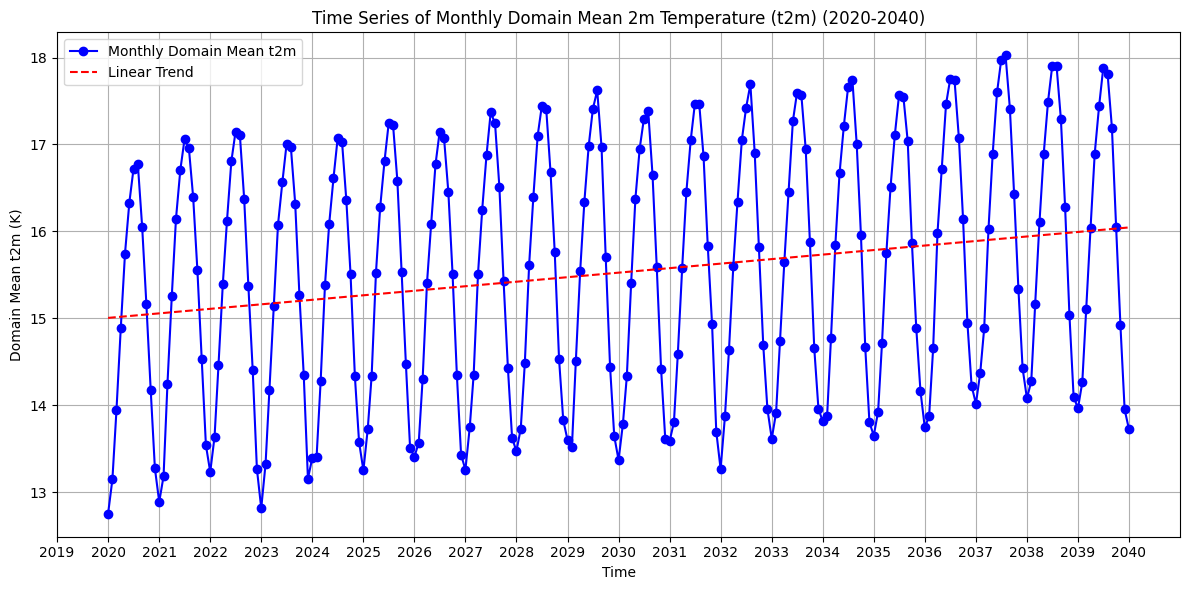

In [3]:
# Plot the time series of monthly domain means
plt.figure(figsize=(12, 6))
plt.plot(time_list, domain_means-273.15, marker="o", linestyle="-", color="b", label="Monthly Domain Mean t2m")

# Add a trend line
# Convert time_list to numerical values for fitting
time_numeric = np.arange(len(time_list))  # Create a numerical index for time

# Fit a linear trend (1st degree polynomial)
trend_coeffs = np.polyfit(time_numeric, domain_means, deg=1)
trend_line = np.polyval(trend_coeffs, time_numeric)

# Plot the trend line
plt.plot(time_list, trend_line-273.15, linestyle="--", color="r", label="Linear Trend")

# Customize the plot
plt.title("Time Series of Monthly Domain Mean 2m Temperature (t2m) (2020-2040)")
plt.xlabel("Time")
plt.ylabel("Domain Mean t2m (K)")
plt.grid(True)
plt.legend()

# Format x-axis to show years
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Y"))
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.YearLocator())

plt.tight_layout()
plt.show()

# 2m temerature trend# Plot for 

In [ ]:
# Plot for mean 2020

In [49]:
# Directory where monthly mean files are stored
monthly_means_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_t2m/"

# Load the monthly mean data for 2020
monthly_mean_2020 = xr.open_dataset(f"{monthly_means_dir}monthly_mean_t2m_2020.nc")

# Extract the t2m variable
t2m_monthly = monthly_mean_2020["t2m"]  # Shape: (month, values)

# Compute the mean over the year (axis=0 is the month dimension)
t2m_mean_2020 = t2m_monthly.mean(dim="month").compute()

# Save the mean map to a NetCDF file (optional)
t2m_mean_2020.to_dataset(name="t2m").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2020.nc")

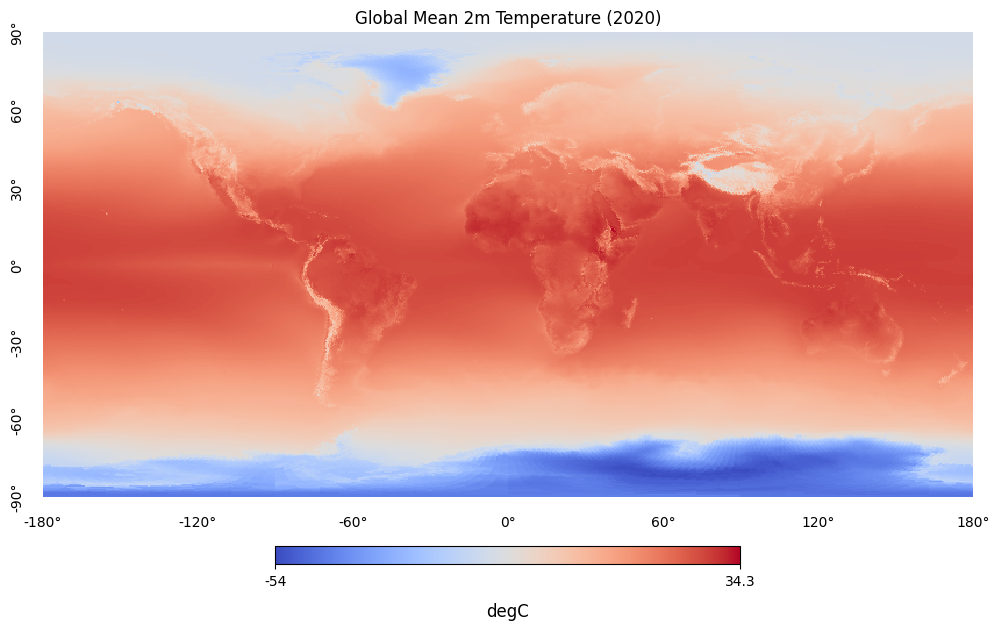

In [50]:
import healpy as hp
import matplotlib.pyplot as plt

# Load the mean map for 2020
t2m_mean_2020 = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2020.nc")["t2m"]

# Extract the HEALPix map (1D array)
healpix_map = t2m_mean_2020.values

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the data using Healpy's cartview
hp.cartview(
    healpix_map-273.15,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Global Mean 2m Temperature (2020)",
    min=None,            # Minimum value for the color scale (auto if None)
    max=None,            # Maximum value for the color scale (auto if None)
    cmap="coolwarm",     # Colormap
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("degC", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

### [2035â€“2039] - [2020â€“2024]

In [4]:
# Compute the Mean for 2035â€“2039

# Directory where monthly mean files are stored
monthly_means_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_t2m/"

# Initialize a list to store annual means for 2035â€“2039
annual_means_2035_2039 = []

# Loop through each year from 2035 to 2039
for year in range(2035, 2040):
    # Load the monthly mean data for the year
    monthly_mean_data = xr.open_dataset(f"{monthly_means_dir}monthly_mean_t2m_{year}.nc")
    
    # Extract the t2m variable
    t2m_monthly = monthly_mean_data["t2m"]  # Shape: (month, values)
    
    # Compute the annual mean (mean over months)
    annual_mean = t2m_monthly.mean(dim="month").compute()
    
    # Append the annual mean to the list
    annual_means_2035_2039.append(annual_mean)

# Compute the mean over the 5-year period (2035â€“2039)
mean_2035_2039 = xr.concat(annual_means_2035_2039, dim="year").mean(dim="year")

# Save the 5-year mean map to a NetCDF file (optional)
mean_2035_2039.to_dataset(name="t2m").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2035_2039.nc")

In [5]:
# Compute the Mean for 2020â€“2024

# Initialize a list to store annual means for 2020â€“2024
annual_means_2020_2024 = []

# Loop through each year from 2020 to 2024
for year in range(2020, 2025):
    # Load the monthly mean data for the year
    monthly_mean_data = xr.open_dataset(f"{monthly_means_dir}monthly_mean_t2m_{year}.nc")
    
    # Extract the t2m variable
    t2m_monthly = monthly_mean_data["t2m"]  # Shape: (month, values)
    
    # Compute the annual mean (mean over months)
    annual_mean = t2m_monthly.mean(dim="month").compute()
    
    # Append the annual mean to the list
    annual_means_2020_2024.append(annual_mean)

# Compute the mean over the 5-year period (2020â€“2024)
mean_2020_2024 = xr.concat(annual_means_2020_2024, dim="year").mean(dim="year")

# Save the 5-year mean map to a NetCDF file (optional)
mean_2020_2024.to_dataset(name="t2m").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2020_2024.nc")

In [3]:
# Load the saved mean files
mean_2020_2024 = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2020_2024.nc")["t2m"]
mean_2035_2039 = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2035_2039.nc")["t2m"]

# Compute difference (2035-2039 minus 2020-2024)
difference_map = mean_2035_2039 - mean_2020_2024

# Save difference map
difference_map.to_dataset(name="t2m").to_netcdf(
    f"{PROJ2559_DIR}/sfc_hr/t2m_difference_2035_2039_minus_2020_2024.nc"
)

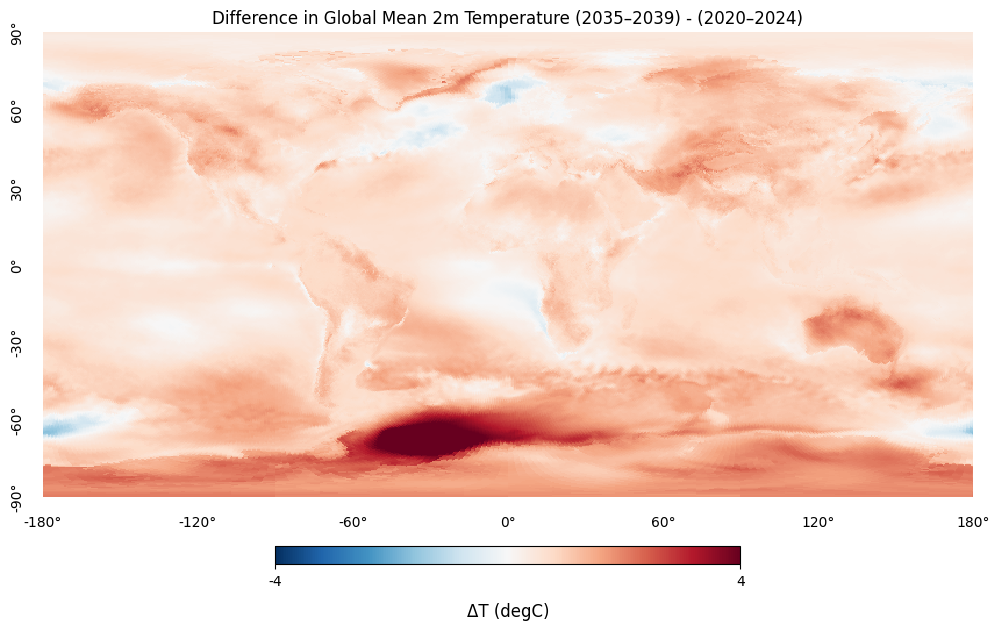

In [5]:
# Plot

# Extract the HEALPix map (1D array)
difference_healpix_map = difference_map.values

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the difference map using Healpy's cartview
hp.cartview(
    difference_healpix_map,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Difference in Global Mean 2m Temperature (2035â€“2039) - (2020â€“2024)",
    min=-4,              # Minimum value for the color scale (fixed to -8 K)
    max=4,               # Maximum value for the color scale (fixed to +3 K)
    cmap="RdBu_r",       # Colormap (red-blue for positive-negative differences)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Î”T (degC)", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

In [6]:
# Create Target Grid & Interpolation Function

import numpy as np
import healpy as hp

# 1Â° resolution grid
grid_lon, grid_lat = np.meshgrid(
    np.linspace(-180, 180, 360),
    np.linspace(-90, 90, 180)
)

def interpolate_healpix(data_array, lons, lats):
    """Interpolate HEALPix data to regular grid"""
    grid_data = np.zeros_like(grid_lat)
    for i,j in np.ndindex(grid_lon.shape):
        grid_data[i,j] = hp.get_interp_val(
            data_array,
            grid_lon[i,j],
            grid_lat[i,j],
            lonlat=True,
            nest=True
        )
    return grid_data

In [7]:
# Process T2M Data
# Load files with consistent variable names
mean_2020_2024 = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2020_2024.nc")["t2m"]
mean_2035_2039 = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2035_2039.nc")["t2m"]

# Interpolate both periods using the same function
grid_2020_2024 = interpolate_healpix(mean_2020_2024.values, 
                                    mean_2020_2024.longitude.values,
                                    mean_2020_2024.latitude.values)
grid_2035_2039 = interpolate_healpix(mean_2035_2039.values,
                                    mean_2035_2039.longitude.values,
                                    mean_2035_2039.latitude.values)

In [15]:
# Compute difference
difference_map = grid_2035_2039 - grid_2020_2024

# Get absolute min/max (ignoring NaNs)
vmin = np.nanmin(difference_map)
vmax = np.nanmax(difference_map)

# Create symmetric levels centered on zero
abs_max = max(abs(vmin), abs(vmax))
levels = np.linspace(-abs_max, abs_max, 21)

print(f"Min difference: {vmin:.2f}Â°C, Max difference: {vmax:.2f}Â°C")
print(f"Using symmetric range: {-abs_max:.2f} to {abs_max:.2f}Â°C")

Min difference: -1.65Â°C, Max difference: 6.64Â°C
Using symmetric range: -6.64 to 6.64Â°C


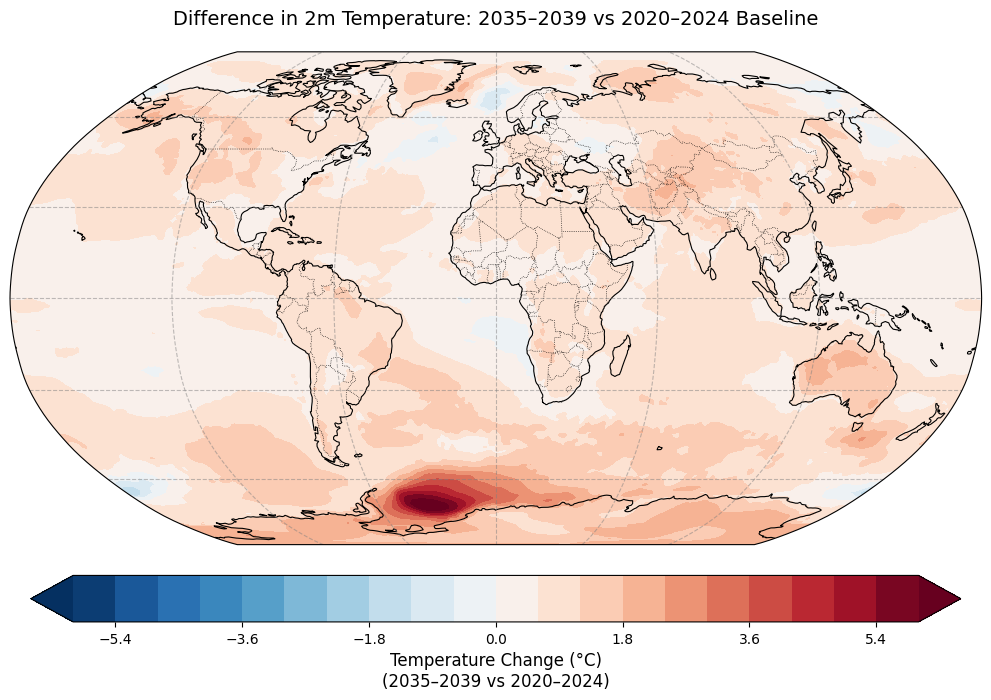

In [14]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# --- Critical Adjustments ---
# 1. Use symmetric color scaling (essential for difference maps)
vmax = max(abs(vmin), abs(vmax))  # Ensure balance around zero
levels = np.linspace(-6.0, 6.0, 21)  # Now perfectly symmetric

# 2. Plot with adjusted levels
plot = ax.contourf(
    grid_lon, grid_lat, difference_map,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",  # Red (positive) vs Blue (negative)
    levels=levels,
    extend="both"    # Show values beyond scale limits
)

# --- Map Features ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.add_feature(cfeature.LAND, color='lightgray', zorder=0)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Colorbar ---
cbar = plt.colorbar(
    plot, 
    orientation='horizontal',
    pad=0.05,
    shrink=0.8
)
cbar.set_label("Temperature Change (Â°C)\n(2035â€“2039 vs 2020â€“2024)", fontsize=12)

# --- Title ---
plt.title("Difference in 2m Temperature: 2035â€“2039 vs 2020â€“2024 Baseline", 
          fontsize=14, pad=20)

plt.show()

In [9]:
print(f"Data range: {vmin:.2f} to {vmax:.2f} Â°C") 
print(f"Global mean change: {np.nanmean(difference_map):.2f} Â°C")
print(f"Max warming: {np.nanmax(difference_map):.2f} Â°C")
print(f"Max cooling: {np.nanmin(difference_map):.2f} Â°C")

Data range: 0.14 to 1.96 Â°C
Global mean change: 0.90 Â°C
Max warming: 6.64 Â°C
Max cooling: -1.65 Â°C


In [13]:
# Compute difference
difference_map = grid_2035_2039 - grid_2020_2024

# Get absolute min/max (ignoring NaNs)
vmin = np.nanmin(difference_map)
vmax = np.nanmax(difference_map)

# Create symmetric levels centered on zero
abs_max = max(abs(vmin), abs(vmax))
levels = np.linspace(-abs_max, abs_max, 21)

print(f"Min difference: {vmin:.2f}Â°C, Max difference: {vmax:.2f}Â°C")
print(f"Using symmetric range: {-abs_max:.2f} to {abs_max:.2f}Â°C")

Min difference: -1.65Â°C, Max difference: 6.64Â°C
Using symmetric range: -6.64 to 6.64Â°C


### 2020 - 2030 : Not Required

In [ ]:
#pip install --upgrade cartopy

In [ ]:
# Calculate the Mean 2m Temperature for 2030

# Directory where monthly mean files are stored
monthly_means_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_t2m/"

# Load the monthly mean data for 2030 and 2039
monthly_mean_2030 = xr.open_dataset(f"{monthly_means_dir}monthly_mean_t2m_2030.nc")
monthly_mean_2039 = xr.open_dataset(f"{monthly_means_dir}monthly_mean_t2m_2039.nc")

# Extract the t2m variable
t2m_monthly_2030 = monthly_mean_2030["t2m"]  # Shape: (month, values)
t2m_monthly_2039 = monthly_mean_2039["t2m"]  # Shape: (month, values)

# Compute the mean over the year (axis=0 is the month dimension)
t2m_mean_2030 = t2m_monthly_2030.mean(dim="month").compute()
t2m_mean_2039 = t2m_monthly_2039.mean(dim="month").compute()

# Save the mean map to a NetCDF file (optional)
t2m_mean_2030.to_dataset(name="t2m").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2030.nc")
t2m_mean_2039.to_dataset(name="t2m").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2039.nc")

In [ ]:
# Compute the Difference Between 2020 and 2030

# Load the mean maps for 2020 and 2030
t2m_mean_2020 = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2020.nc")["t2m"]
t2m_mean_2030 = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2030.nc")["t2m"]

# Compute the difference (2020 - 2030)
difference_map30 = t2m_mean_2020 - t2m_mean_2030

# Save the difference map to a NetCDF file (optional)
difference_map30.to_dataset(name="t2m").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_difference_2020_2030.nc")

In [ ]:
# Plot

# Extract the HEALPix map (1D array)
difference_healpix_map = difference_map30.values

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the difference map using Healpy's cartview with fixed temperature range
hp.cartview(
    difference_healpix_map,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Difference in Global Mean 2m Temperature (2020 - 2030)",
    min=-8,              # Minimum value for the color scale (fixed to -8 K)
    max=3,               # Maximum value for the color scale (fixed to +3 K)
    cmap="RdBu_r",       # Colormap (red-blue for positive-negative differences)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Î”T (degC)", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

### 2020 - 2039 : Not Required

In [ ]:
# Compute the Difference Between 2020 and 2039

# Load the mean maps for 2020 and 2030
t2m_mean_2020 = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2020.nc")["t2m"]
t2m_mean_2039 = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_mean_2039.nc")["t2m"]

# Compute the difference (2020 - 2030)
difference_map39 = t2m_mean_2020 - t2m_mean_2039

# Save the difference map to a NetCDF file (optional)
difference_map39.to_dataset(name="t2m").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_difference_2020_2039.nc")

In [ ]:

# Extract the HEALPix map (1D array)
difference_healpix_map39 = difference_map39.values

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the difference map using Healpy's cartview with fixed temperature range
hp.cartview(
    difference_healpix_map39,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Difference in Global Mean 2m Temperature (2020 - 2039)",
    min=-8,              # Minimum value for the color scale (fixed to -8 K)
    max=3,               # Maximum value for the color scale (fixed to +3 K)
    cmap="RdBu_r",       # Colormap (red-blue for positive-negative differences)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Î”T (degC)", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

### Trend plot : 2020 - 2024

In [ ]:
import xarray as xr
import numpy as np

# Directory where annual mean files are stored
annual_means_dir = f"{PROJ2559_DIR}/sfc_hr/annual_means/"

# Initialize a list to store annual mean data
annual_means = []

# Loop through each year from 2020 to 2024
for year in range(2020, 2025):
    # Load the annual mean data for the year
    annual_mean_data = xr.open_dataset(f"{annual_means_dir}annual_mean_t2m_{year}.nc")
    
    # Extract the t2m variable
    annual_mean = annual_mean_data["t2m"]  # Shape: (values,)
    
    # Append the annual mean to the list
    annual_means.append(annual_mean)

# Combine the annual means into a single xarray.DataArray
annual_means = xr.concat(annual_means, dim="year")

In [ ]:
from scipy.stats import linregress

# Create an array to store the trend values (slopes)
trend_values = np.zeros(annual_means.shape[1])  # Shape: (values,)

# Loop through each grid point
for i in range(annual_means.shape[1]):
    # Extract the time series for the current grid point
    time_series = annual_means[:, i].values  # Shape: (years,)
    
    # Perform linear regression
    slope, _, _, _, _ = linregress(np.arange(len(time_series)), time_series)
    
    # Store the slope (trend) in Â°C/year
    trend_values[i] = slope

# Convert the trend values to an xarray.DataArray
trend_map = xr.DataArray(
    trend_values,
    dims=["values"],
    coords={"values": annual_means["values"]},
    attrs={"units": "Â°C/year"},
)

# Save the trend map to a NetCDF file (optional)
trend_map.to_dataset(name="t2m_trend").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_trend_2020_2024.nc")

In [ ]:
import healpy as hp
import matplotlib.pyplot as plt

# Extract the HEALPix map (1D array)
trend_healpix_map = trend_map.values

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the trend map using Healpy's cartview
hp.cartview(
    trend_healpix_map,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Trend in Global Mean 2m Temperature (2020â€“2024)",
    min=None,            # Minimum value for the color scale (auto if None)
    max=None,            # Maximum value for the color scale (auto if None)
    cmap="RdBu_r",       # Colormap (red-blue for positive-negative trends)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Trend (Â°C/year)", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

### Trend plot : 2020 - 2039

In [2]:
import xarray as xr
import numpy as np

# Directory where annual mean files are stored
annual_means_dir = f"{PROJ2559_DIR}/sfc_hr/annual_means/"

# Initialize a list to store annual mean data
annual_means = []

# Loop through each year from 2020 to 2039
for year in range(2020, 2040):
    # Load the annual mean data for the year
    annual_mean_data = xr.open_dataset(f"{annual_means_dir}annual_mean_t2m_{year}.nc")
    
    # Extract the t2m variable
    annual_mean = annual_mean_data["t2m"]  # Shape: (values,)
    
    # Append the annual mean to the list
    annual_means.append(annual_mean)

# Combine the annual means into a single xarray.DataArray
annual_means = xr.concat(annual_means, dim="year")

In [9]:
from scipy.stats import linregress

# Create an array to store the trend values (slopes)
trend_values = np.zeros(annual_means.shape[1])  # Shape: (values,)

# Loop through each grid point
for i in range(annual_means.shape[1]):
    # Extract the time series for the current grid point
    time_series = annual_means[:, i].values  # Shape: (years,)
    
    # Perform linear regression
    slope, _, _, _, _ = linregress(np.arange(len(time_series)), time_series)
    
    # Store the slope (trend) in Â°C/year
    trend_values[i] = slope

# Convert the trend values to an xarray.DataArray
trend_map = xr.DataArray(
    trend_values,
    dims=["values"],
    coords={"values": annual_means["values"]},
    attrs={"units": "Â°C/year"},
)

# Save the trend map to a NetCDF file (optional)
trend_map.to_dataset(name="t2m_trend").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_trend_2020_2039.nc")

KeyboardInterrupt: 

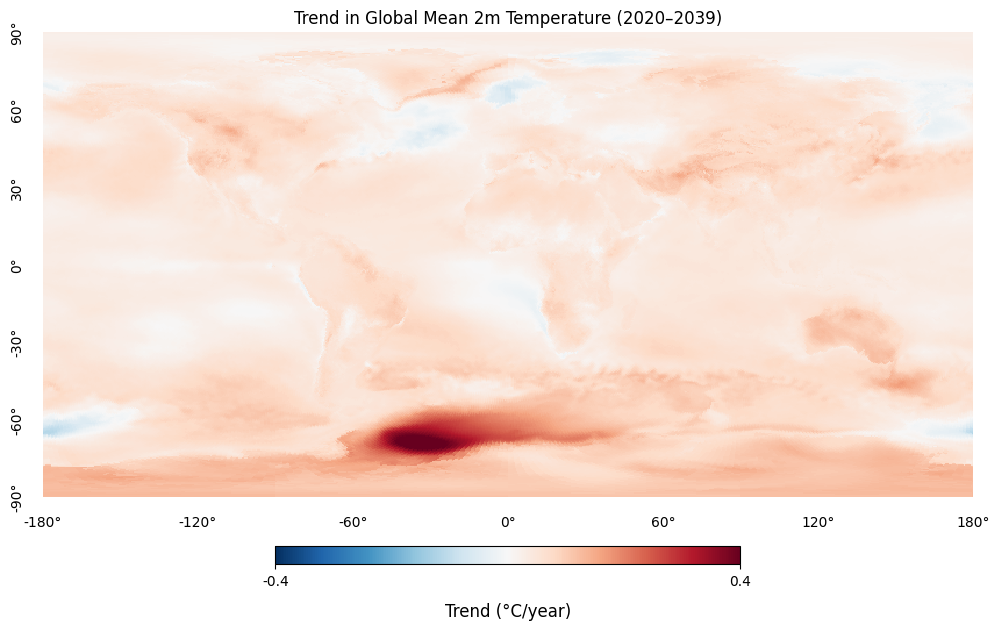

In [3]:
import healpy as hp
import matplotlib.pyplot as plt

# Load the trend map for 2020â€“2039
trend_map = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_trend_2020_2039.nc")["t2m_trend"]

# Extract the HEALPix map (1D array)
trend_healpix_map = trend_map.values

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the trend map using Healpy's cartview
hp.cartview(
    trend_healpix_map,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Trend in Global Mean 2m Temperature (2020â€“2039)",
    min=-0.4,            # Minimum value for the color scale (auto if None)
    max=0.4,            # Maximum value for the color scale (auto if None)
    cmap="RdBu_r",       # Colormap (red-blue for positive-negative trends)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Trend (Â°C/year)", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

### Extremes

#### Hotspots

In [13]:
import xarray as xr

# Load the trend map for 2020â€“2039
trend_map = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_trend_2020_2039.nc")["t2m_trend"]

# Extract the HEALPix map (1D array)
trend_healpix_map = trend_map.values

In [14]:
# Verify HEALPix Data

import healpy as hp
import numpy as np

# Get the HEALPix resolution (NSIDE) from the trend_map
nside = hp.npix2nside(len(trend_healpix_map))  # Number of pixels = len(trend_healpix_map)
print(f"HEALPix NSIDE: {nside}")
print(f"Number of pixels: {len(trend_healpix_map)}")
print(f"Trend values min: {np.min(trend_healpix_map)}, max: {np.max(trend_healpix_map)}")

HEALPix NSIDE: 128
Number of pixels: 196608
Trend values min: -0.11436760694460761, max: 0.4447082748986725


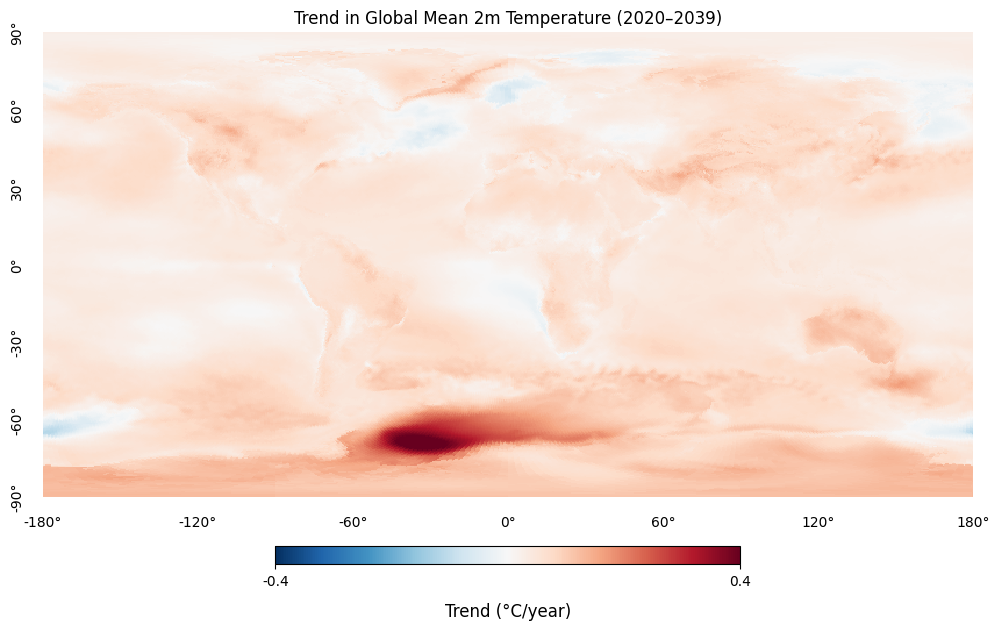

In [15]:
# Plot the Trend Map Using healpy.cartview

import matplotlib.pyplot as plt

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the trend map using Healpy's cartview
hp.cartview(
    trend_healpix_map,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Trend in Global Mean 2m Temperature (2020â€“2039)",
    min=-0.4,            # Minimum value for the color scale (auto if None)
    max=0.4,             # Maximum value for the color scale (auto if None)
    cmap="RdBu_r",       # Colormap (red-blue for positive-negative trends)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Trend (Â°C/year)", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

In [16]:
# Create a regular latitude/longitude grid
grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 180), np.linspace(-180, 180, 360))

# Convert HEALPix data to a regular grid using bilinear interpolation
grid_trend = np.zeros_like(grid_lat)
for i in range(grid_lat.shape[0]):
    for j in range(grid_lat.shape[1]):
        # Ensure longitude is in the range [-180, 180]
        lon = grid_lon[i, j]
        if lon > 180:
            lon -= 360
        grid_trend[i, j] = hp.get_interp_val(trend_healpix_map, lon, grid_lat[i, j], lonlat=True, nest=True)

# Check the interpolated data
print(f"Interpolated trend values min: {np.nanmin(grid_trend)}, max: {np.nanmax(grid_trend)}")

Interpolated trend values min: -0.11289309854428922, max: 0.44357200913930095


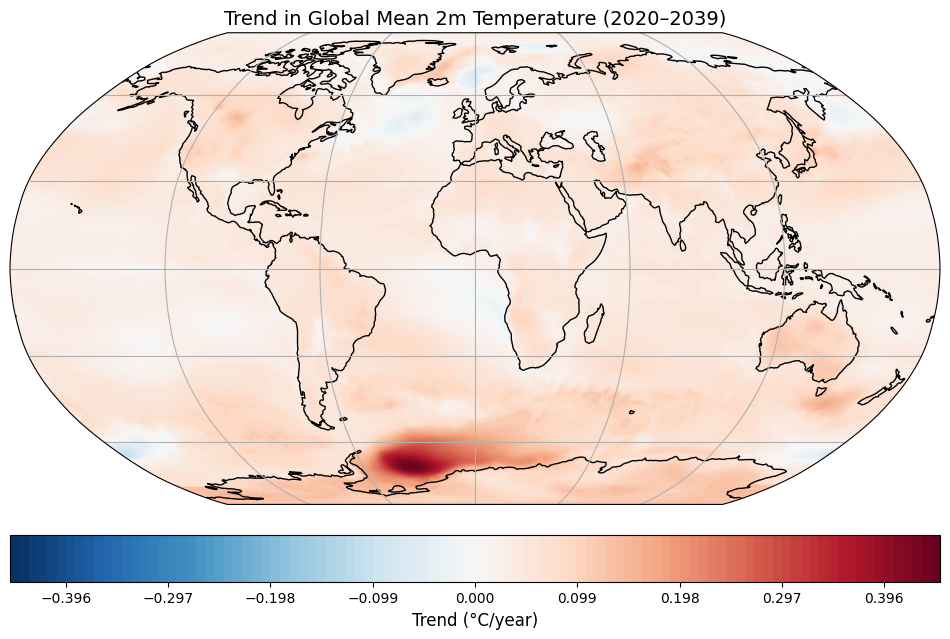

In [17]:
import cartopy.crs as ccrs

# Create a figure
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Plot the trend map
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",  # Red-blue colormap for positive/negative trends
    levels=np.linspace(-0.45, 0.45, 101),  # Color scale from -0.4 to 0.4 Â°C/year
)

# Add coastlines and gridlines
ax.coastlines()
ax.gridlines()

# Add a colorbar
cbar = plt.colorbar(trend_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label("Trend (Â°C/year)", fontsize=12)

# Add a title
plt.title("Trend in Global Mean 2m Temperature (2020â€“2039)", fontsize=14)

# Show the plot
plt.show()

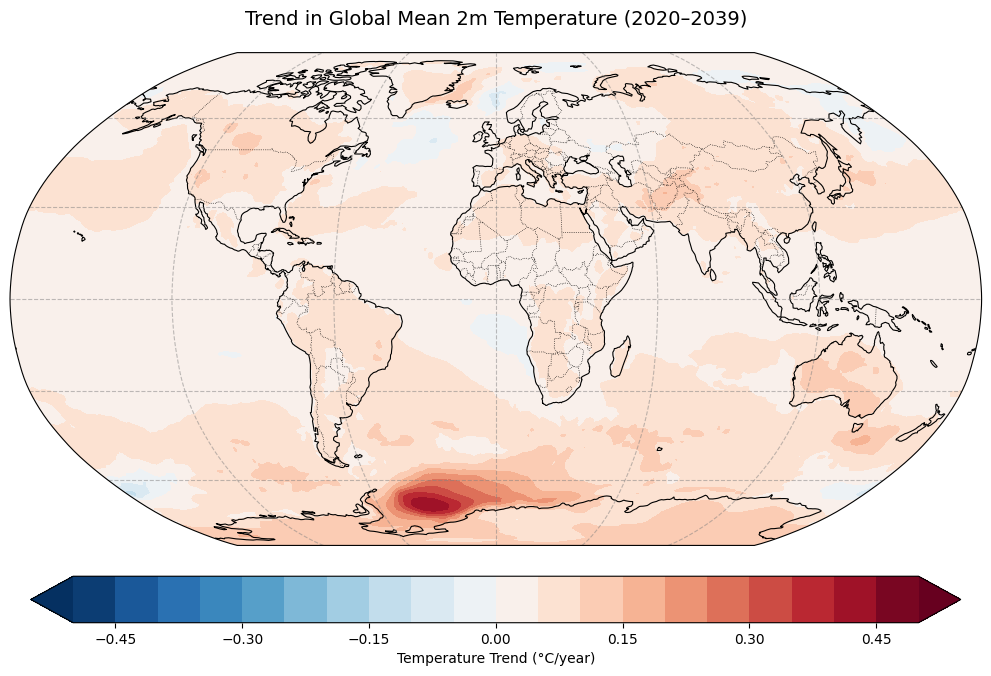

In [10]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Create figure
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# --- Plot Temperature Trend ---
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),
    extend="both"
)

# --- Add Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Add Colorbar ---
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8)
cbar.set_label("Temperature Trend (Â°C/year)")

# --- Add Title ---
plt.title("Trend in Global Mean 2m Temperature (2020â€“2039)", fontsize=14, pad=20)
plt.show()


#### Warm

In [11]:
# Define the Positive Hotspot Mask

# Define the threshold for positive hotspots
positive_threshold = 0.1  # Â°C/year

# Create a mask for positive hotspots (trend >= positive_threshold)
positive_hotspot_mask = grid_trend >= positive_threshold

In [12]:
# Normalize the Positive Hotspot Trend Values

# Define the range for shading positive hotspots (0.4 to 0.45 Â°C/year)
positive_shading_min = positive_threshold                  # 0.4
positive_shading_max = 0.45

# Normalize the positive hotspot trend values within the shading range
normalized_positive_hotspot_trend = (grid_trend - positive_shading_min) / (positive_shading_max - positive_shading_min)

# Clip values outside the range (0 to 1)
normalized_positive_hotspot_trend = np.clip(normalized_positive_hotspot_trend, 0, 1)

# Apply the positive hotspot mask
# Overlay the Positive Hotspots on the Trend Mapnormalized_positive_hotspot_trend[~positive_hotspot_mask] = np.nan  # Set non-hotspots to NaN

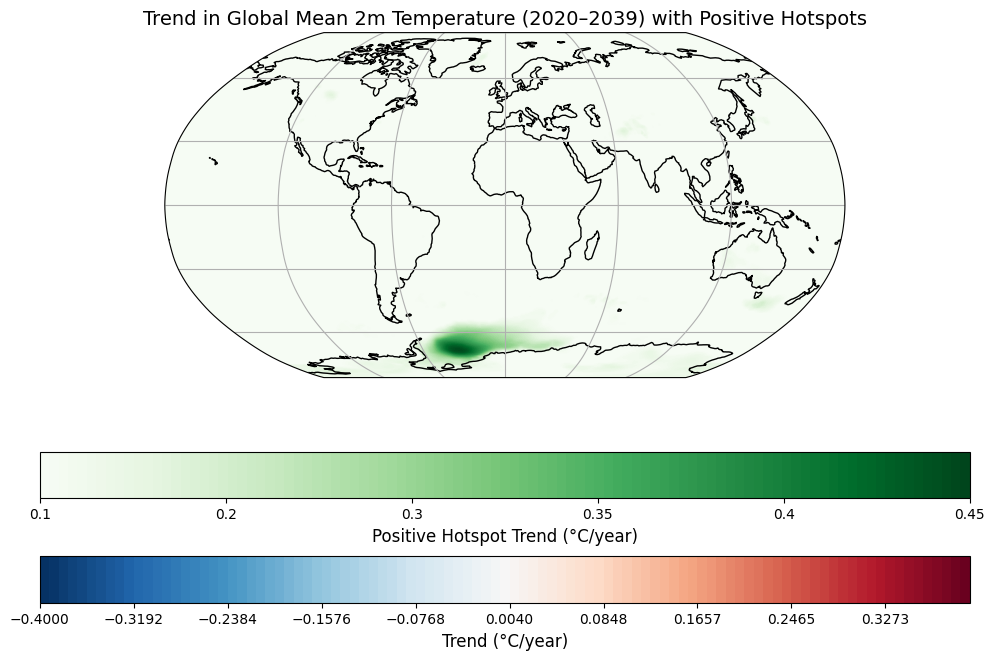

In [13]:
# Overlay the Positive Hotspots on the Trend Map

import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create a figure
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Plot the trend map
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",  # Red-blue colormap for positive/negative trends
    levels=np.linspace(-0.4, 0.4, 100),  # Color scale from -0.4 to 0.4 Â°C/year
)

# Overlay the positive hotspots
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="Greens",  # Green colormap for positive hotspots
    levels=np.linspace(0, 1, 100),  # Smooth color scale
)

# Add coastlines and gridlines
ax.coastlines()
ax.gridlines()

# Add a colorbar for the trend map
cbar_trend = plt.colorbar(trend_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar_trend.set_label("Trend (Â°C/year)", fontsize=12)

# Add a colorbar for the positive hotspots
cbar_positive = plt.colorbar(positive_hotspot_plot, ax=ax, orientation="horizontal", pad=0.15)
cbar_positive.set_label("Positive Hotspot Trend (Â°C/year)", fontsize=12)
cbar_positive.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_positive.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])  # Actual values

# Add a title
plt.title("Trend in Global Mean 2m Temperature (2020â€“2039) with Positive Hotspots", fontsize=14)

# Show the plot
plt.show()


# # Add a colorbar (customized placement and style)
# cbar_ax = fig.add_axes([0.25, 0.12, 0.5, 0.02])  # [left, bottom, width, height]

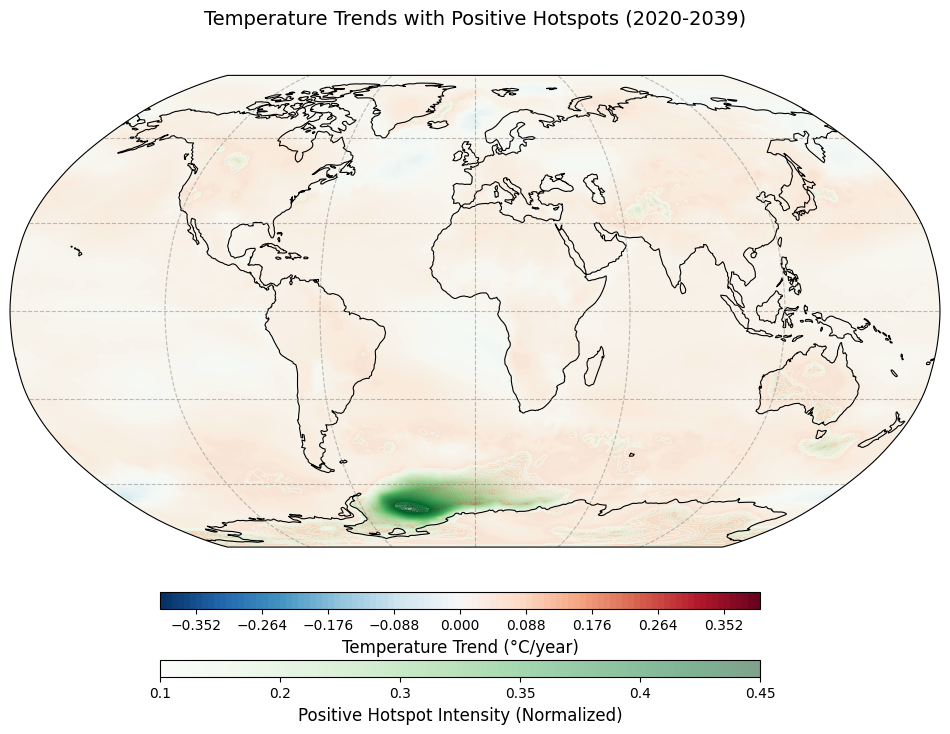

In [14]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create figure with adjusted dimensions
fig = plt.figure(figsize=(12, 8.5))  # Slightly taller than original

ax = plt.axes(projection=ccrs.Robinson())

# --- Main Plots ---
# Temperature trend
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.45, 0.45, 101)
)

# Positive hotspots overlay
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="Greens",
    levels=np.linspace(0, 1, 100),
    alpha=0.5
)

# --- Map Elements ---
ax.coastlines(linewidth=0.8)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Title (positioned at top) ---
plt.title("Temperature Trends with Positive Hotspots (2020-2039)", 
          fontsize=14, pad=20, y=1.05)  # y=1.05 moves title slightly higher

# --- Colorbar 1: Temperature Trend ---
cbar_trend_ax = fig.add_axes([0.25, 0.13, 0.5, 0.02])  # Position matches your reference
cbar_trend = fig.colorbar(trend_plot, cax=cbar_trend_ax,
                         orientation="horizontal")
cbar_trend.set_label("Temperature Trend (Â°C/year)", fontsize=12)

# --- Colorbar 2: Positive Hotspots --- 
cbar_hotspot_ax = fig.add_axes([0.25, 0.05, 0.5, 0.02])  # Positioned below first
cbar_hotspot = fig.colorbar(positive_hotspot_plot, cax=cbar_hotspot_ax,
                          orientation="horizontal")
cbar_hotspot.set_label("Positive Hotspot Intensity (Normalized)", fontsize=12)
cbar_hotspot.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_hotspot.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])

# Adjust overall plot spacing
plt.subplots_adjust(top=0.85)  # Creates space for title without overlapping

plt.show()

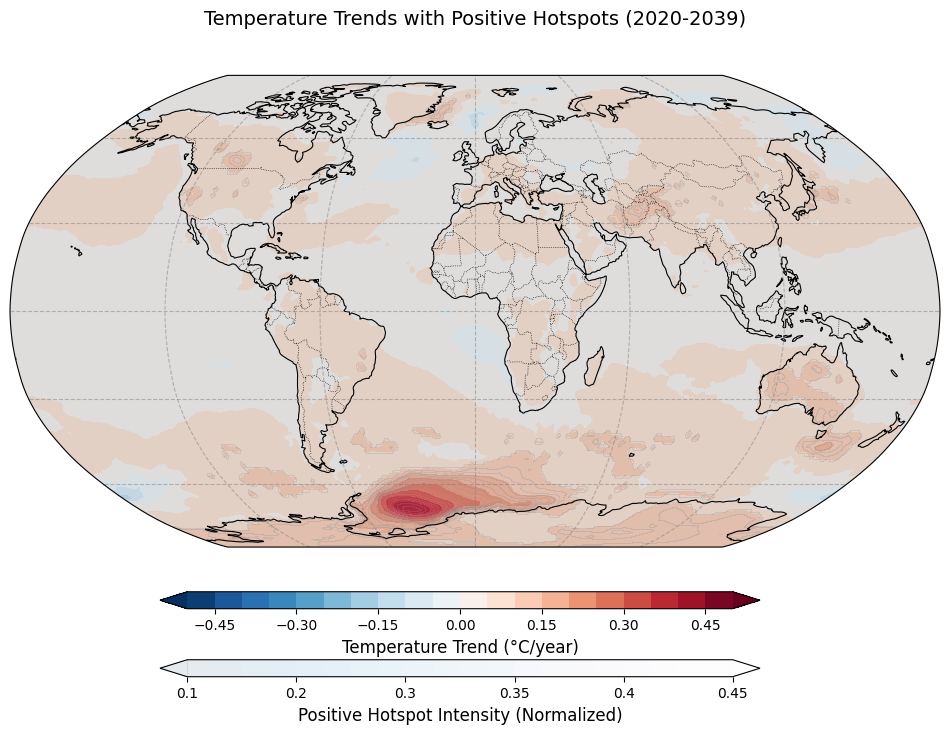

In [22]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np

# Create figure with adjusted dimensions
fig = plt.figure(figsize=(12, 8.5))  # Slightly taller than original
ax = plt.axes(projection=ccrs.Robinson())

# --- Main Plots ---
# Temperature trend
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),  # Ensures distinct contour colors
    extend="both"
)

# Positive hotspots overlay
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="PuBu_r",
    levels=np.linspace(0, 1, 21),  # Adjusted for better contrast
    alpha=0.1,
    extend="both"
)

# --- Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Title (positioned at top) ---
plt.title("Temperature Trends with Positive Hotspots (2020-2039)", 
          fontsize=14, pad=20, y=1.05)  # y=1.05 moves title slightly higher

# --- Colorbar 1: Temperature Trend ---
cbar_trend_ax = fig.add_axes([0.25, 0.13, 0.5, 0.02])  # Position matches your reference
cbar_trend = fig.colorbar(trend_plot, cax=cbar_trend_ax,
                         orientation="horizontal", extend='both')
cbar_trend.set_label("Temperature Trend (Â°C/year)", fontsize=12)

# --- Colorbar 2: Positive Hotspots --- 
cbar_hotspot_ax = fig.add_axes([0.25, 0.05, 0.5, 0.02])  # Positioned below first
cbar_hotspot = fig.colorbar(positive_hotspot_plot, cax=cbar_hotspot_ax,
                          orientation="horizontal", extend='both')
cbar_hotspot.set_label("Positive Hotspot Intensity (Normalized)", fontsize=12)
cbar_hotspot.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_hotspot.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])

# Adjust overall plot spacing
plt.subplots_adjust(top=0.85)  # Creates space for title without overlapping

plt.show()


#### Warm & Cool

In [61]:
# Define the Negative Hotspot Mask

# Define the threshold for negative hotspots
negative_threshold = -0.04  # Â°C/year

# Create a mask for negative hotspots (trend <= negative_threshold)
negative_hotspot_mask = grid_trend <= negative_threshold

In [62]:
# Normalize the Negative Hotspot Trend Values

# Define the range for shading negative hotspots (-0.114 to -0.04 Â°C/year)
negative_shading_min = -0.114
negative_shading_max = negative_threshold             # -0.04

# Normalize the negative hotspot trend values within the shading range
normalized_negative_hotspot_trend = (grid_trend - negative_shading_min) / (negative_shading_max - negative_shading_min)

# Clip values outside the range (0 to 1)
normalized_negative_hotspot_trend = np.clip(normalized_negative_hotspot_trend, 0, 1)

# Apply the negative hotspot mask
normalized_negative_hotspot_trend[~negative_hotspot_mask] = np.nan  # Set non-hotspots to NaN

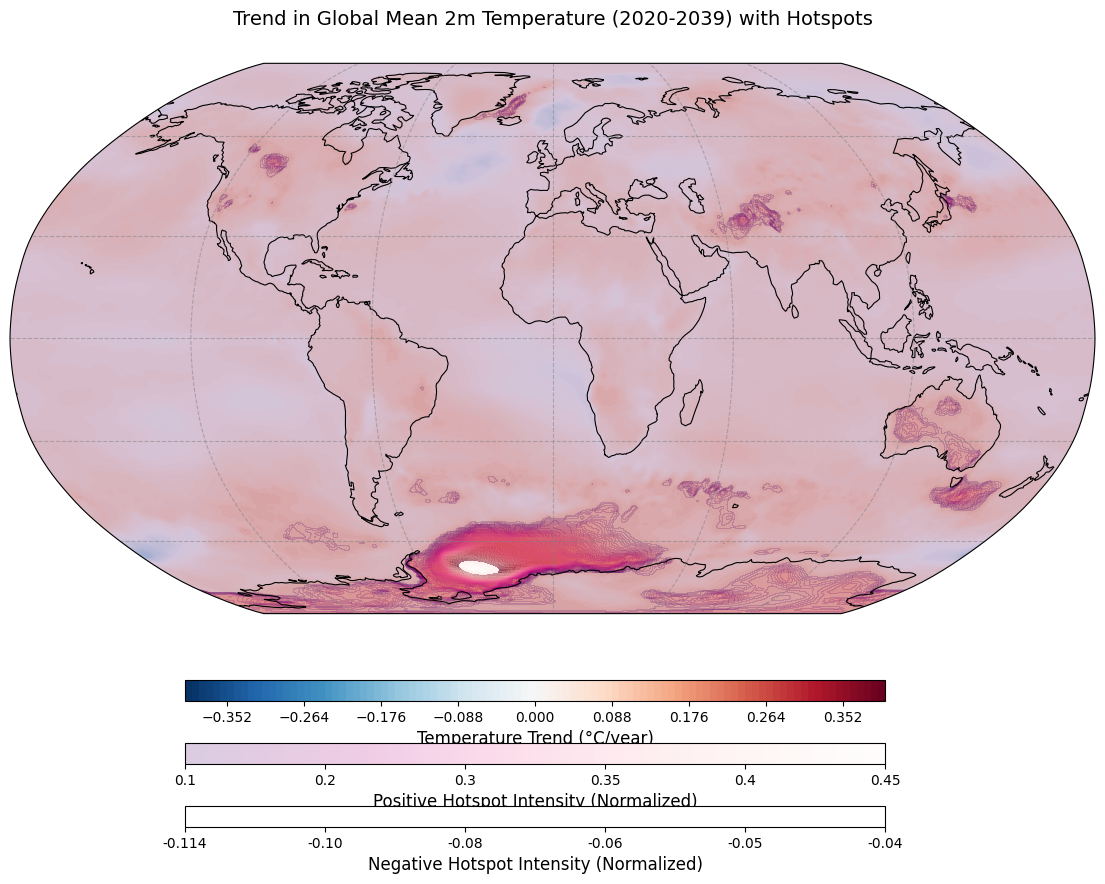

In [42]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create figure with adjusted dimensions
fig = plt.figure(figsize=(14, 10.5))  # Increased height to accommodate colorbars
ax = plt.axes(projection=ccrs.Robinson())

# --- Main Plots ---
# Temperature trend
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.4, 0.4, 101)
)

# Hotspots overlays
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdPu_r",
    levels=np.linspace(0, 1, 100),
    alpha=0.2
)

negative_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_negative_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="PuBu",
    levels=np.linspace(0, 1, 100),
    alpha=0
)

# --- Map Elements ---
ax.coastlines(linewidth=0.8)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Title ---
plt.title("Trend in Global Mean 2m Temperature (2020-2039) with Hotspots", 
          fontsize=14, pad=20, y=1.02)

# --- Colorbar 1: Temperature Trend ---
cbar_trend_ax = fig.add_axes([0.25, 0.18, 0.5, 0.02])  # Highest position
cbar_trend = fig.colorbar(trend_plot, cax=cbar_trend_ax,
                        orientation="horizontal")
cbar_trend.set_label("Temperature Trend (Â°C/year)", fontsize=12)

# --- Colorbar 2: Positive Hotspots ---
cbar_pos_ax = fig.add_axes([0.25, 0.12, 0.5, 0.02])  # Middle position
cbar_pos = fig.colorbar(positive_hotspot_plot, cax=cbar_pos_ax,
                       orientation="horizontal")
cbar_pos.set_label("Positive Hotspot Intensity (Normalized)", fontsize=12)
cbar_pos.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_pos.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])

# --- Colorbar 3: Negative Hotspots ---
cbar_neg_ax = fig.add_axes([0.25, 0.06, 0.5, 0.02])  # Lowest position
cbar_neg = fig.colorbar(negative_hotspot_plot, cax=cbar_neg_ax,
                       orientation="horizontal")
cbar_neg.set_label("Negative Hotspot Intensity (Normalized)", fontsize=12)
cbar_neg.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_neg.set_ticklabels(["-0.114", "-0.10", "-0.08", "-0.06", "-0.05", "-0.04"])

# Adjust layout
plt.subplots_adjust(top=0.85, bottom=0.2)  # Creates space for title and colorbars

plt.show()

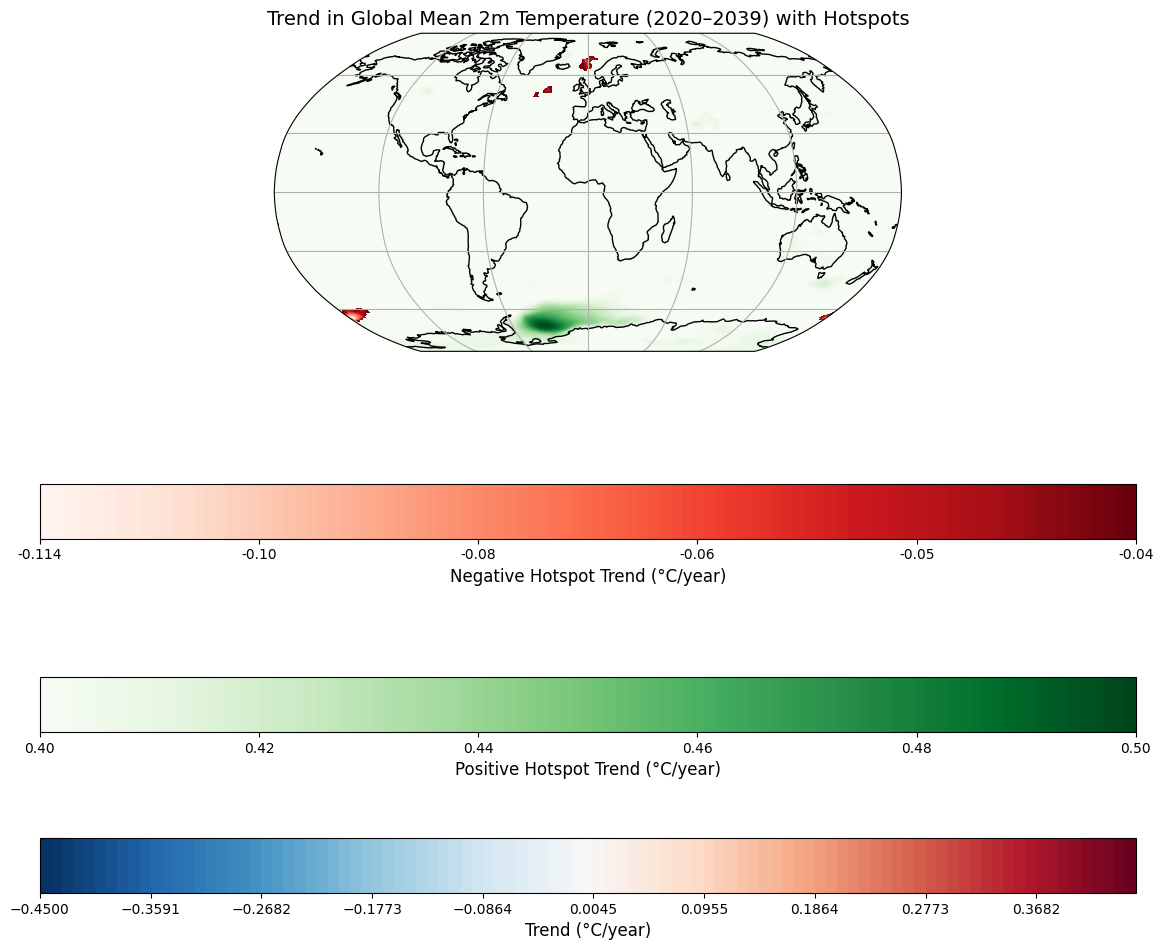

In [64]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create a larger figure to fix the size issue
fig = plt.figure(figsize=(14, 10))  # Increased figure size
ax = plt.axes(projection=ccrs.Robinson())

# Plot the trend map
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",  # Red-blue colormap for positive/negative trends
    levels=np.linspace(-0.45, 0.45, 100),  # Color scale from -0.114 to 0.445 Â°C/year
)

# Overlay the positive hotspots
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="Greens",  # Green colormap for positive hotspots
    levels=np.linspace(0, 1, 100),  # Smooth color scale
)

# Overlay the negative hotspots
negative_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_negative_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="Reds",  # Red colormap for negative hotspots
    levels=np.linspace(0, 1, 100),  # Smooth color scale
)

# Add coastlines and gridlines
ax.coastlines()
ax.gridlines()

# Add a colorbar for the trend map
cbar_trend = plt.colorbar(trend_plot, ax=ax, orientation="horizontal", pad=0.05, shrink=0.8)
cbar_trend.set_label("Trend (Â°C/year)", fontsize=12)

# Add a colorbar for the positive hotspots
cbar_positive = plt.colorbar(positive_hotspot_plot, ax=ax, orientation="horizontal", pad=0.15, shrink=0.8)
cbar_positive.set_label("Positive Hotspot Trend (Â°C/year)", fontsize=12)
cbar_positive.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_positive.set_ticklabels(["0.40", "0.42", "0.44", "0.46", "0.48", "0.50"])  # Actual values

# Add a colorbar for the negative hotspots
cbar_negative = plt.colorbar(negative_hotspot_plot, ax=ax, orientation="horizontal", pad=0.25, shrink=0.8)
cbar_negative.set_label("Negative Hotspot Trend (Â°C/year)", fontsize=12)
cbar_negative.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_negative.set_ticklabels(["-0.114", "-0.10", "-0.08", "-0.06", "-0.05", "-0.04"])  # Actual values

# Add a title
plt.title("Trend in Global Mean 2m Temperature (2020â€“2039) with Hotspots", fontsize=14)

# Adjust layout to make the map larger
plt.tight_layout()

# Show the plot
plt.show()

/tmp/ipykernel_1550669/3251824895.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


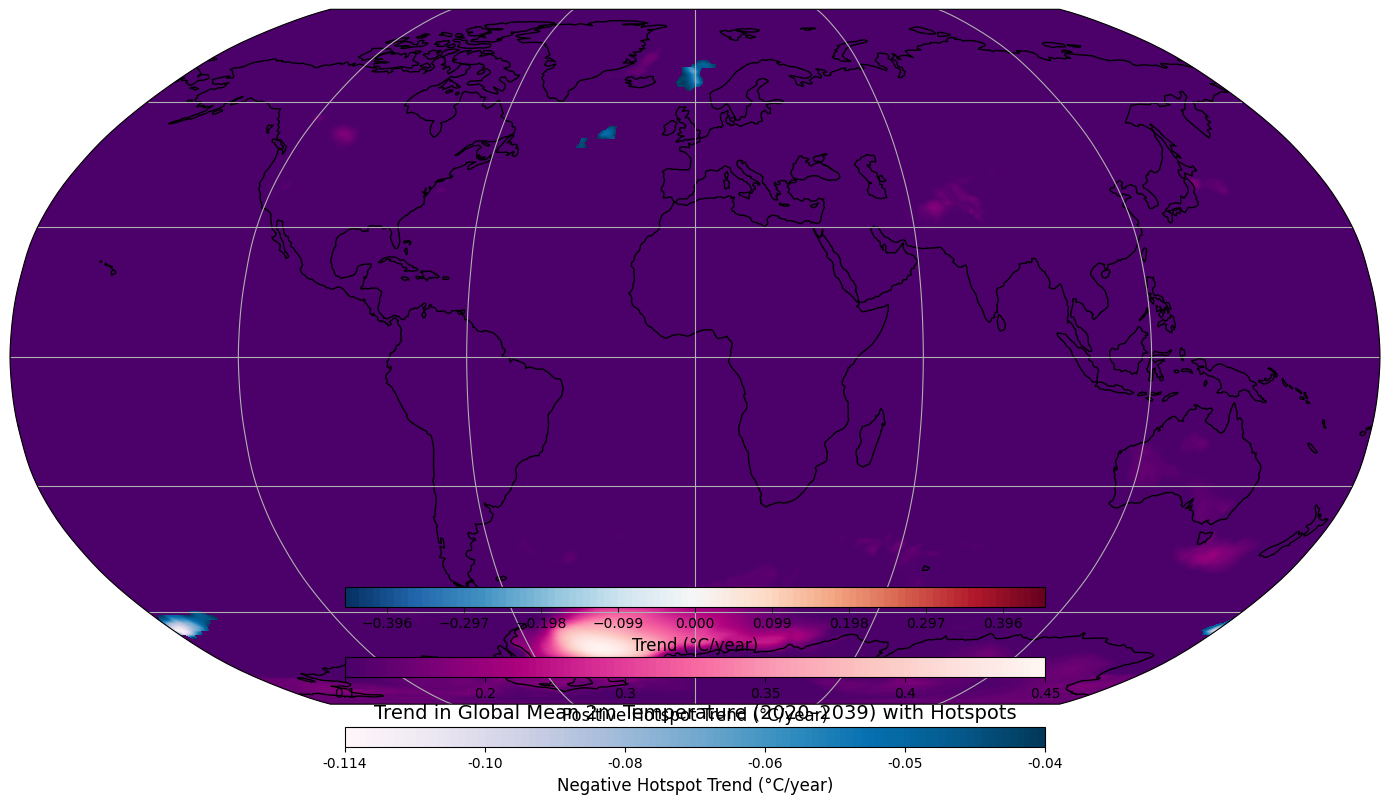

In [38]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create figure (using your original size)
fig = plt.figure(figsize=(14, 10))
ax = plt.axes(projection=ccrs.Robinson())

# --- Main Plots ---
# Temperature trend (unchanged)
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.45, 0.45, 101)
)

# Positive hotspots (unchanged from working version)
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdPu_r",
    levels=np.linspace(0, 1, 100)
)

# Negative hotspots (modified)
negative_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_negative_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="PuBu",  # Using standard PuBu without _r
    levels=np.linspace(0, 1, 100)
)

# --- Map Elements ---
ax.coastlines()
ax.gridlines()

# --- Colorbar 1: Temperature Trend ---
cbar_trend_ax = fig.add_axes([0.25, 0.25, 0.5, 0.02])
cbar_trend = fig.colorbar(trend_plot, cax=cbar_trend_ax, orientation="horizontal")
cbar_trend.set_label("Trend (Â°C/year)", fontsize=12)

# --- Colorbar 2: Positive Hotspots ---
cbar_pos_ax = fig.add_axes([0.25, 0.18, 0.5, 0.02])
cbar_pos = fig.colorbar(positive_hotspot_plot, cax=cbar_pos_ax, orientation="horizontal")
cbar_pos.set_label("Positive Hotspot Trend (Â°C/year)", fontsize=12)
cbar_pos.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_pos.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])

# --- Colorbar 3: Negative Hotspots ---
cbar_neg_ax = fig.add_axes([0.25, 0.11, 0.5, 0.02])
cbar_neg = fig.colorbar(negative_hotspot_plot, cax=cbar_neg_ax, orientation="horizontal")
cbar_neg.set_label("Negative Hotspot Trend (Â°C/year)", fontsize=12)
cbar_neg.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_neg.set_ticklabels(["-0.114", "-0.10", "-0.08", "-0.06", "-0.05", "-0.04"])

# --- Title ---
plt.title("Trend in Global Mean 2m Temperature (2020â€“2039) with Hotspots", fontsize=14)
plt.tight_layout()
plt.show()

#### ITCZ

In [2]:
# Define the output directory where monthly mean files are stored
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_tpr/"

# List of monthly mean files
monthly_files = [f"{output_dir}monthly_mean_tpr_{year}.nc" for year in range(2020, 2040)]

In [3]:
import xarray as xr
import pandas as pd

# Function to add time coordinates to a dataset
def add_time_coords(ds, year):
    # Create a time coordinate for each month
    time = pd.date_range(start=f"{year}-01-01", periods=12, freq="M")
    ds = ds.assign_coords(time=time)
    return ds

# Load one monthly mean file to inspect
sample_file = f"{output_dir}monthly_mean_tprate_2020.nc"
ds_sample = xr.open_dataset(sample_file)

# Add time coordinates to the dataset
ds_sample = add_time_coords(ds_sample, 2020)

# Print the updated dataset
print(ds_sample)

<xarray.Dataset>
Dimensions:    (values: 196608, month: 12, time: 12)
Coordinates:
    step       timedelta64[ns] ...
    surface    float64 ...
    latitude   (values) float64 ...
    longitude  (values) float64 ...
  * month      (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
  * time       (time) datetime64[ns] 2020-01-31 2020-02-29 ... 2020-12-31
Dimensions without coordinates: values
Data variables:
    tprate     (month, values) float32 ...


In [4]:
# Loop through each year and add time coordinates
datasets = []
for year in range(2020, 2040):
    file_path = f"{output_dir}monthly_mean_tprate_{year}.nc"
    ds = xr.open_dataset(file_path)
    ds = add_time_coords(ds, year)
    datasets.append(ds)

# Concatenate all datasets along the time dimension
ds = xr.concat(datasets, dim="time")

# Print the concatenated dataset
print(ds)

<xarray.Dataset>
Dimensions:    (values: 196608, month: 12, time: 240)
Coordinates:
    step       timedelta64[ns] 00:00:00
    surface    float64 0.0
    latitude   (values) float64 0.2984 0.5968 0.5968 ... -0.5968 -0.5968 -0.2984
    longitude  (values) float64 45.0 45.35 44.65 45.0 ... 315.4 314.6 315.0
  * month      (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
  * time       (time) datetime64[ns] 2020-01-31 2020-02-29 ... 2039-12-31
Dimensions without coordinates: values
Data variables:
    tprate     (time, month, values) float32 1.74e-06 1.926e-06 ... 1.293e-05


In [5]:
# Group by year and compute the annual mean
annual_means = ds["tprate"].groupby("time.year").mean(dim="time")

# Print the annual means
print("Annual means:")
print(annual_means)

Annual means:
<xarray.DataArray 'tprate' (year: 20, month: 12, values: 196608)>
array([[[1.73986564e-06, 1.92589278e-06, 1.50021799e-06, ...,
         2.10373735e-04, 1.98912690e-04, 1.22968238e-04],
        [6.71783411e-08, 1.35684076e-07, 3.69719011e-08, ...,
         6.96036150e-05, 9.54554052e-05, 5.84559712e-05],
        [1.09560347e-06, 1.31893557e-06, 1.49145819e-06, ...,
         1.18547388e-04, 8.28589473e-05, 5.81606691e-05],
        ...,
        [1.83178181e-05, 2.21302616e-05, 1.93262986e-05, ...,
         1.29208468e-06, 1.99873307e-06, 9.67386200e-07],
        [6.46347689e-06, 8.91649051e-06, 8.71009161e-06, ...,
         2.99239605e-06, 2.76035985e-06, 3.15622060e-06],
        [1.21879827e-06, 2.12022837e-06, 9.51315940e-07, ...,
         2.54048809e-05, 3.06703769e-05, 2.93956564e-05]],

       [[1.93912896e-07, 2.58514575e-07, 2.07026474e-07, ...,
         6.71116941e-05, 8.36091567e-05, 6.69955116e-05],
        [6.30527595e-08, 1.73611284e-07, 1.32816027e-07, ...,
   

In [9]:
print(annual_means.shape)

(20, 12, 196608)


In [6]:
# Select time periods directly from the full dataset
period1_ds = ds.sel(time=slice("2020-01-01", "2024-12-31"))  # 2020-2024 (60 months)
period2_ds = ds.sel(time=slice("2035-01-01", "2039-12-31"))  # 2035-2039 (60 months)

# Compute mean over ALL months (collapsing both time and month dimensions)
period1_mean_all_months = period1_ds["tprate"].mean(dim=["time", "month"])  # Shape: (196608,)
period2_mean_all_months = period2_ds["tprate"].mean(dim=["time", "month"])  # Shape: (196608,)

print("2020-2024 mean shape:", period1_mean_all_months.shape)  # Should be (196608,)
print("2035-2039 mean shape:", period2_mean_all_months.shape)  # Should be (196608,)

2020-2024 mean shape: (196608,)
2035-2039 mean shape: (196608,)


In [7]:
period1_mean_mmday = period1_mean_all_months * 86400

period2_mean_mmday = period2_mean_all_months * 86400

print("2020-2024:")
print(f"Min: {np.min(period1_mean_mmday):.2f} mm/day, Max: {np.max(period1_mean_mmday):.2f} mm/day")

print("2035-2039:")
print(f"Min: {np.min(period2_mean_mmday):.2f} mm/day, Max: {np.max(period2_mean_mmday):.2f} mm/day")

2020-2024:
Min: 0.00 mm/day, Max: 42.68 mm/day
2035-2039:
Min: 0.00 mm/day, Max: 44.91 mm/day


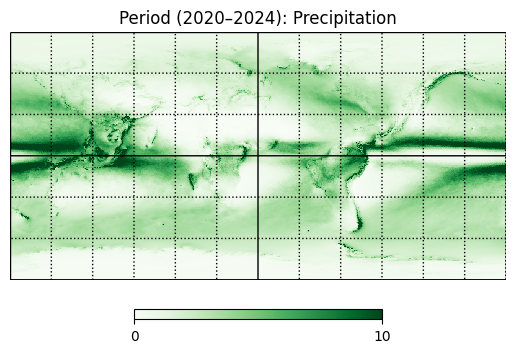

In [33]:
import healpy as hp
import matplotlib.pyplot as plt

# # Compute the long-term mean across all years and months
# long_term_mean = ds["tcc"].mean(dim=["time", "month"])

# Plot the long-term mean using healpy.cartview
hp.cartview(
    period1_mean_mmday.values,  # HEALPix data
    nest=True,              # Use NESTED ordering
    title="Period (2020â€“2024): Precipitation",
    min=0,                  # Minimum value for the color scale
    max=10,                  # Maximum value for the color scale
    cmap="Greens",           # Colormap for cloud cover
    badcolor="gray",        # Color for invalid/missing data
    hold=True,              # Hold the plot for further customization
)

# Add latitude and longitude labels
hp.graticule()

# Show the plot
plt.show()

In [ ]:
print(long_term_mean.shape)

In [8]:
## Plot in Robinson projection

import numpy as np

# Define the target grid (180x360)
grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 180), np.linspace(-180, 180, 360))

In [9]:
import healpy as hp

# Initialize the interpolated grid
grid_period1 = np.zeros_like(grid_lat)
grid_period2 = np.zeros_like(grid_lat)

# Perform interpolation
for i in range(grid_lat.shape[0]):
    for j in range(grid_lat.shape[1]):
        lon = grid_lon[i, j]
        lat = grid_lat[i, j]
        
        # Ensure longitude is in the range [-180, 180]
        if lon > 180:
            lon -= 360
        
        # Interpolate the HEALPix data
        grid_period1[i, j] = hp.get_interp_val(period1_mean_mmday.values, lon, lat, lonlat=True, nest=True)
        grid_period2[i, j] = hp.get_interp_val(period2_mean_mmday.values, lon, lat, lonlat=True, nest=True)

# Replace NaN values in the interpolated data
grid_period1 = np.nan_to_num(grid_period1, nan=0)
grid_period2 = np.nan_to_num(grid_period2, nan=0)

# Check the interpolated data
print(f"Interpolated Precipitation rate values (2020-2024) min: {np.nanmin(grid_period1)}, max: {np.nanmax(grid_period1)}")
print(f"Interpolated data shape: {grid_period1.shape}")
print(f"Interpolated Precipitation rate values (2035-2039) min: {np.nanmin(grid_period2)}, max: {np.nanmax(grid_period2)}")
print(f"Interpolated data shape: {grid_period2.shape}")

Interpolated Precipitation rate values (2020-2024) min: 0.0017145454854155158, max: 29.042133870208332
Interpolated data shape: (360, 180)
Interpolated Precipitation rate values (2035-2039) min: 0.0003349938774944394, max: 31.912427510038754
Interpolated data shape: (360, 180)


/tmp/ipykernel_649881/608167638.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


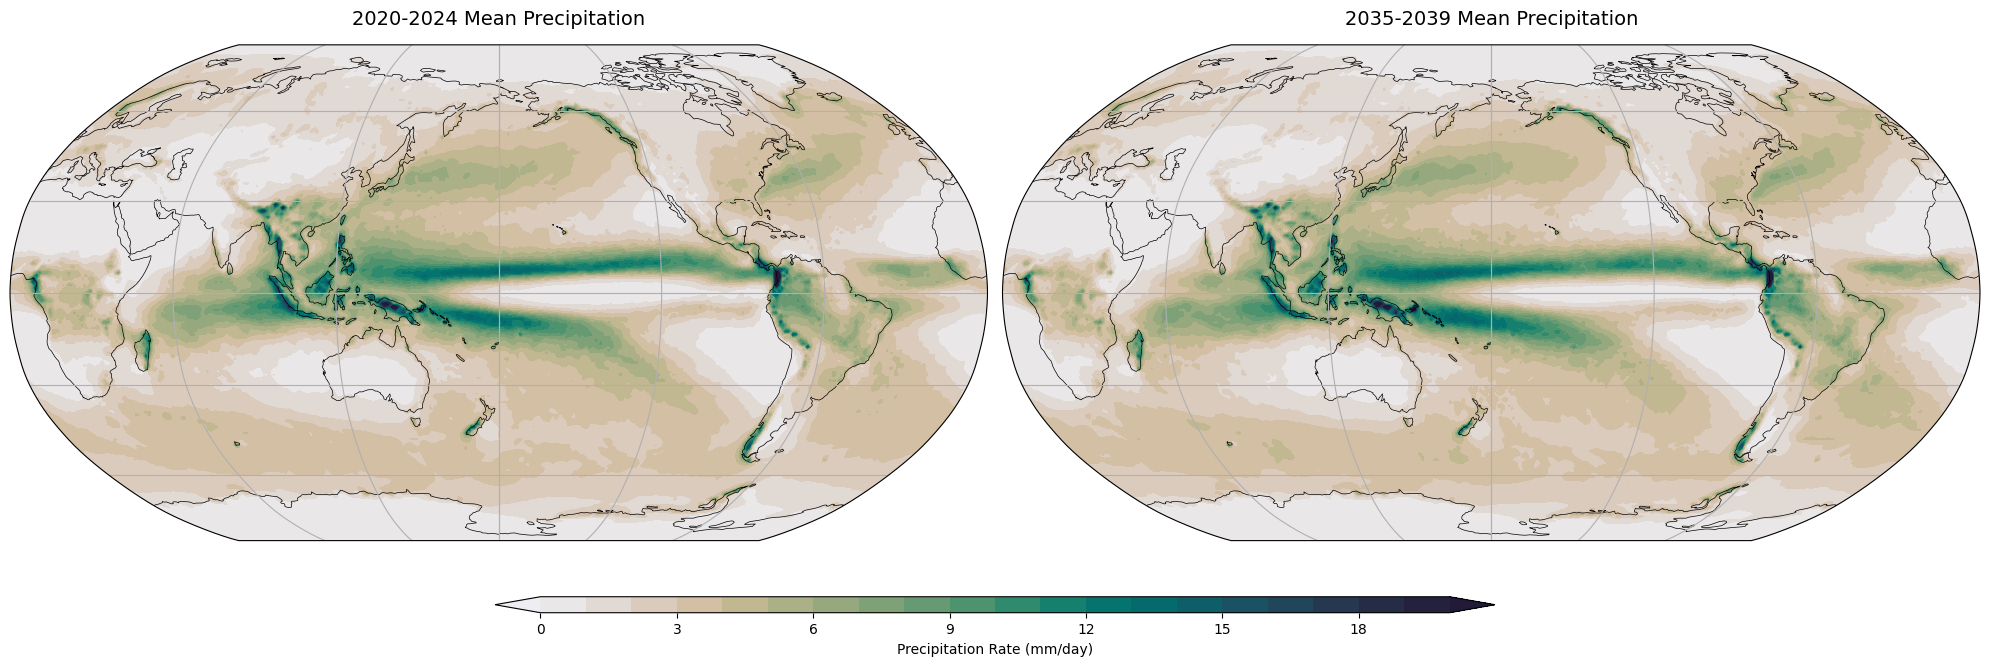

In [29]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8),
                              subplot_kw={'projection': ccrs.Robinson(central_longitude=180)})

# Common parameters for both plots
levels = np.linspace(0, 20, 21)
cmap = cmo.rain

# Plot first period (2020-2024)
precip1 = ax1.contourf(
    grid_lon, grid_lat, grid_period1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="both"
)
ax1.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax1.gridlines()
ax1.set_title("2020-2024 Mean Precipitation", fontsize=14, pad=15)

# Plot second period (2035-2039)
precip2 = ax2.contourf(
    grid_lon, grid_lat, grid_period2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="both"
)
ax2.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax2.gridlines()
ax2.set_title("2035-2039 Mean Precipitation", fontsize=14, pad=15)

# Add single colorbar (corrected - no fontsize parameter)
cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.02])
cbar = fig.colorbar(precip1, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Precipitation Rate (mm/day)")  # Set label after creation

plt.tight_layout()
plt.show()

In [11]:
# 1. Calculate Zonal Mean Precipitation

# Compute zonal mean (average over longitude)
zonal_mean_p1 = np.mean(grid_period1, axis=0)  # Shape: (180,)
zonal_mean_p2 = np.mean(grid_period2, axis=0)  # Shape: (180,)

# Corresponding latitudes
latitudes = np.linspace(-90, 90, 180)

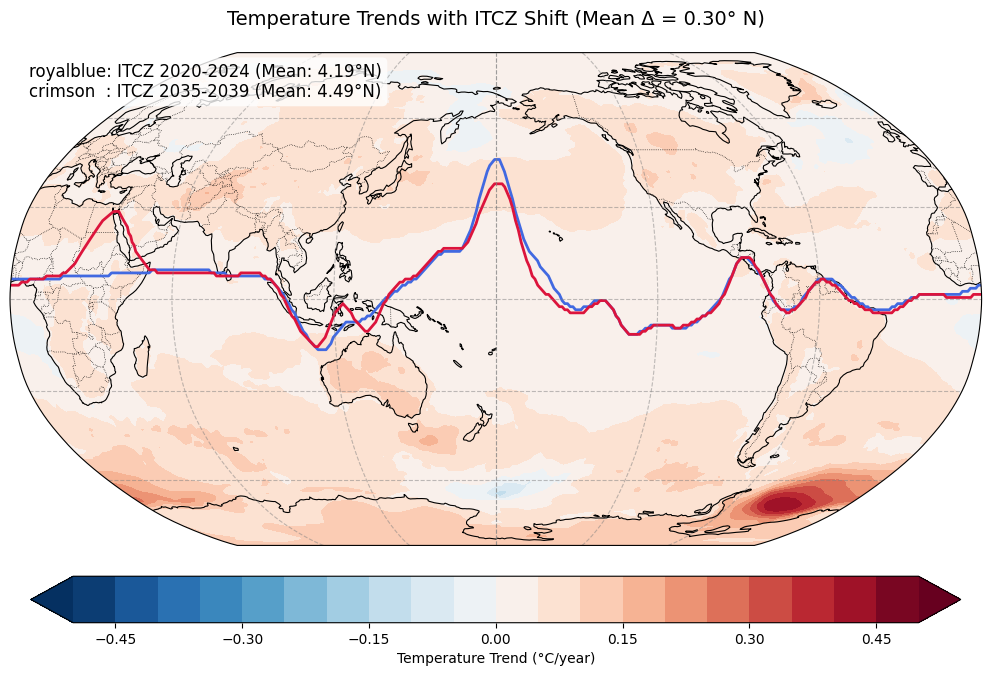

In [28]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from scipy.ndimage import gaussian_filter1d  # <-- Missing import

# Create figure
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# --- Plot Temperature Trend ---
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),
    extend="both"
)

# --- Calculate ITCZ Lines with Smoothing ---
def get_smoothed_itcz(precip_grid, sigma=5):
    """Returns smoothed ITCZ latitude at each longitude"""
    # First find raw ITCZ position (index of max precip at each longitude)
    itcz_idx = np.argmax(precip_grid, axis=1)  # shape: (360,)
    
    # Smooth the indices before converting to latitude
    smoothed_idx = gaussian_filter1d(itcz_idx.astype(float), sigma=sigma)
    
    # Convert indices to latitudes (-90 to 90Â°)
    return np.linspace(-90, 90, 180)[smoothed_idx.astype(int)]

# Get ITCZ positions
itcz_p1 = get_smoothed_itcz(grid_period1)  # 2020-2024
itcz_p2 = get_smoothed_itcz(grid_period2)  # 2035-2039
longitudes = np.linspace(0, 360, 360)

# --- Overlay ITCZ Lines ---
ax.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
        color='royalblue', linewidth=2, label='ITCZ 2020-2024')
ax.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
        color='crimson', linewidth=2, label='ITCZ 2035-2039')

# --- Add Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2)

# --- Add Colorbar ---
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8)
cbar.set_label("Temperature Trend (Â°C/year)")

# --- Calculate and Display Mean Shift ---
mean_shift = np.mean(itcz_p2 - itcz_p1)
plt.title(f"Temperature Trends with ITCZ Shift (Mean Î” = {mean_shift:.2f}Â° N)", 
          fontsize=14, pad=20)

# --- Add Textbox Legend ---
legend_text = [
    f"royalblue: ITCZ 2020-2024 (Mean: {np.mean(itcz_p1):.2f}Â°N)",
    f"crimson  : ITCZ 2035-2039 (Mean: {np.mean(itcz_p2):.2f}Â°N)"
]

# Create a white semi-transparent box
textbox = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none')

# Position the text in upper left
ax.text(0.02, 0.98,  # x,y in axes coordinates (0-1)
        '\n'.join(legend_text),
        transform=ax.transAxes,
        verticalalignment='top',
        bbox=textbox,
        fontsize=12)

plt.show()

In [ ]:
# --- Calculate ITCZ Lines with Smoothing ---
def get_smoothed_itcz(precip_grid, sigma=1):
    """Returns smoothed ITCZ latitude at each longitude"""
    # First find raw ITCZ position (index of max precip at each longitude)
    itcz_idx = np.argmax(precip_grid, axis=1)  # shape: (360,)
    
    # Smooth the indices before converting to latitude
    smoothed_idx = gaussian_filter1d(itcz_idx.astype(float), sigma=sigma)
    
    # Convert indices to latitudes (-90 to 90Â°)
    return np.linspace(-90, 90, 180)[smoothed_idx.astype(int)]


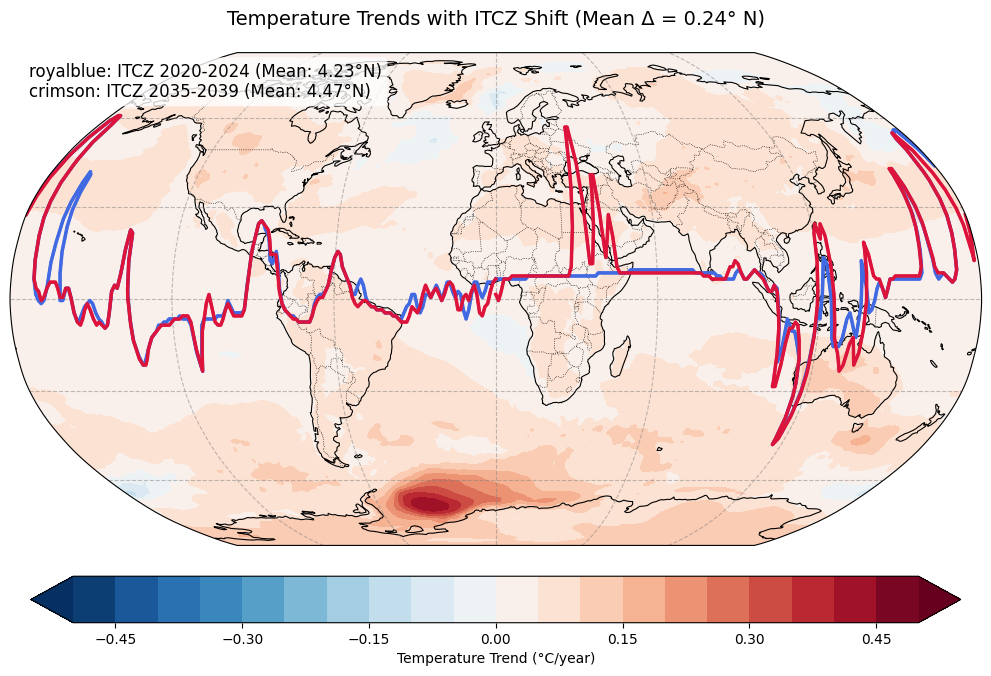

In [22]:
# Create figure
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# --- Plot Temperature Trend ---
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),
    extend="both"
)

# Get ITCZ positions
itcz_p1 = get_smoothed_itcz(grid_period1)  # 2020-2024
itcz_p2 = get_smoothed_itcz(grid_period2)  # 2035-2039
longitudes = np.linspace(0, 360, 360)

# --- Overlay ITCZ Lines ---
ax.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
        color='royalblue', linewidth=2, label='ITCZ 2020-2024')
ax.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
        color='crimson', linewidth=2, label='ITCZ 2035-2039')

# --- Add Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2)

# --- Add Colorbar ---
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8)
cbar.set_label("Temperature Trend (Â°C/year)")

# --- Calculate and Display Mean Shift ---
mean_shift = np.mean(itcz_p2 - itcz_p1)
plt.title(f"Temperature Trends with ITCZ Shift (Mean Î” = {mean_shift:.2f}Â° N)", 
          fontsize=14, pad=20)

# --- Overlay ITCZ Lines with Enhanced Labels ---
itcz_line1 = ax.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
                    color='royalblue', linewidth=2.5, 
                    label='ITCZ 2020-2024 (Mean: {:.2f}Â°N)'.format(np.mean(itcz_p1)))[0]

itcz_line2 = ax.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
                    color='crimson', linewidth=2.5, 
                    label='ITCZ 2035-2039 (Mean: {:.2f}Â°N)'.format(np.mean(itcz_p2)))[0]

# --- Add Textbox Legend ---
legend_text = [
    f"royalblue: ITCZ 2020-2024 (Mean: {np.mean(itcz_p1):.2f}Â°N)",
    f"crimson: ITCZ 2035-2039 (Mean: {np.mean(itcz_p2):.2f}Â°N)"
]

# Create a white semi-transparent box
textbox = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none')

# Position the text in upper left
ax.text(0.02, 0.98,  # x,y in axes coordinates (0-1)
        '\n'.join(legend_text),
        transform=ax.transAxes,
        verticalalignment='top',
        bbox=textbox,
        fontsize=12)
plt.show()

## Climatology Comparison

### ERA5 (Checking data)

In [2]:
dset = xr.open_dataset(f'{ERA5_DIR}/E5sf00_1M_1950-2014_167_st_r1440x721.nc')

dset.coords['lon'] = (dset.coords['lon'] + 180) % 360 - 180
dset = dset.sortby(dset.lon)

data_era_2t= dset['var167'] - 273.15
data_era_2t

<xarray.DataArray 'var167' (time: 780, lat: 721, lon: 1440)>
array([[[-28.845718, -28.845718, -28.843765, ..., -28.847672,
         -28.847672, -28.847672],
        [-28.898453, -28.898453, -28.8965  , ..., -28.902359,
         -28.902359, -28.900406],
        [-29.29103 , -29.285172, -29.283218, ..., -29.300797,
         -29.29689 , -29.294937],
        ...,
        [-31.742203, -31.742203, -31.744156, ..., -31.738297,
         -31.738297, -31.74025 ],
        [-31.712906, -31.712906, -31.712906, ..., -31.710953,
         -31.710953, -31.712906],
        [-31.709   , -31.709   , -31.709   , ..., -31.707047,
         -31.709   , -31.709   ]],

       [[-39.55696 , -39.55696 , -39.55696 , ..., -39.564774,
         -39.560867, -39.558914],
        [-39.527664, -39.527664, -39.52571 , ..., -39.535477,
         -39.533524, -39.53157 ],
        [-39.310867, -39.305008, -39.29915 , ..., -39.328445,
         -39.322586, -39.316727],
...
        [-20.637604, -20.639557, -20.639557, ..., -20.633698,
         -20.63565 , -20.63565 ],
        [-20.727448, -20.7294  , -20.7294  , ..., -20.725494,
         -20.725494, -20.727448],
        [-20.74112 , -20.74112 , -20.74112 , ..., -20.739166,
         -20.739166, -20.739166]],

       [[-27.212967, -27.211014, -27.211014, ..., -27.21492 ,
         -27.212967, -27.212967],
        [-27.275467, -27.275467, -27.273514, ..., -27.279373,
         -27.27742 , -27.27742 ],
        [-27.74617 , -27.742264, -27.738358, ..., -27.757889,
         -27.753983, -27.750076],
        ...,
        [-20.947342, -20.951248, -20.953201, ..., -20.93953 ,
         -20.941483, -20.945389],
        [-20.791092, -20.793045, -20.794998, ..., -20.787186,
         -20.789139, -20.789139],
        [-20.77156 , -20.77156 , -20.773514, ..., -20.765701,
         -20.767654, -20.769608]]], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 1950-01-01T12:00:00 ... 2014-12-01T12:00:00
  * lon      (lon) float64 -180.0 -179.8 -179.5 -179.2 ... 179.2 179.5 179.8
  * lat      (lat) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75 90.0

#### Original resolution

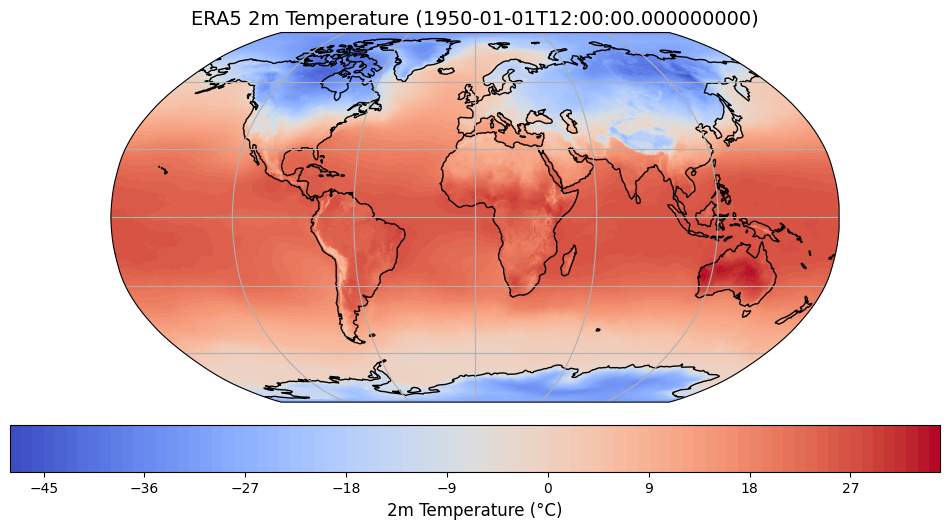

In [5]:
# Plot the ERA5 Data in Its Original Resolution : first timestep

import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# # Load the ERA5 data
# dset = xr.open_dataset(f'{ERA5_DIR}/E5sf00_1M_1950-2014_167_st_r1440x721.nc')

# Adjust longitude to the range [-180, 180]
dset.coords['lon'] = (dset.coords['lon'] + 180) % 360 - 180
dset = dset.sortby(dset.lon)

# Convert temperature from Kelvin to Celsius
data_era_2t = dset['var167'] - 273.15

# Select a time step for plotting (e.g., the first time step)
time_step = 0
era5_2t_snapshot = data_era_2t.isel(time=time_step)

# Create a figure
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Plot the ERA5 data
era5_plot = ax.contourf(
    era5_2t_snapshot.lon, era5_2t_snapshot.lat, era5_2t_snapshot,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",  # Colormap for temperature
    levels=100,       # Number of color levels
)

# Add coastlines and gridlines
ax.coastlines()
ax.gridlines()

# Add a colorbar
cbar = plt.colorbar(era5_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label("2m Temperature (Â°C)", fontsize=12)

# Add a title
plt.title(f"ERA5 2m Temperature ({era5_2t_snapshot.time.values})", fontsize=14)

# Show the plot
plt.show()

####  Model resolution

In [10]:
import numpy as np
from scipy.interpolate import RegularGridInterpolator

# Define your model grid (180x360)
model_lat = np.linspace(-90, 90, 180)
model_lon = np.linspace(-180, 180, 360)
model_lon_grid, model_lat_grid = np.meshgrid(model_lon, model_lat)

# Extract ERA5 latitude and longitude
era5_lat = era5_2t_snapshot.lat.values
era5_lon = era5_2t_snapshot.lon.values

# Create an interpolator for the ERA5 data
era5_interpolator = RegularGridInterpolator(
    (era5_lat, era5_lon),  # Input grid (latitude, longitude)
    era5_2t_snapshot.values,  # Input data
    method="linear",  # Interpolation method
    bounds_error=False,  # Allow extrapolation
    fill_value=np.nan,  # Fill value for extrapolation
)

# Interpolate ERA5 data to the model grid
era5_interpolated = era5_interpolator((model_lat_grid, model_lon_grid))

# Check the interpolated data
print(f"Interpolated ERA5 values min: {np.nanmin(era5_interpolated)}, max: {np.nanmax(era5_interpolated)}")

Interpolated ERA5 values min: -46.84180523443524, max: 34.268343494993644


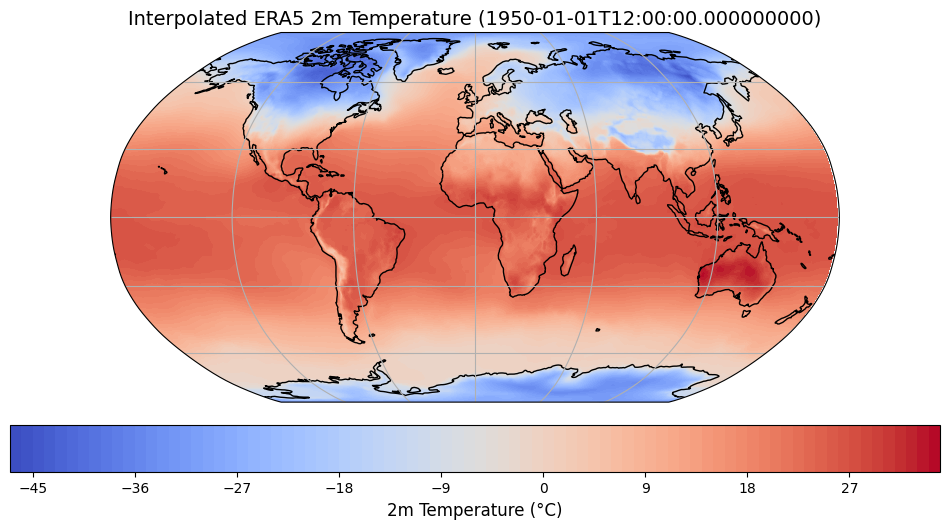

In [11]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create a figure
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Plot the interpolated ERA5 data
era5_interp_plot = ax.contourf(
    model_lon_grid, model_lat_grid, era5_interpolated,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",  # Colormap for temperature
    levels=100,       # Number of color levels
)

# Add coastlines and gridlines
ax.coastlines()
ax.gridlines()

# Add a colorbar
cbar = plt.colorbar(era5_interp_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label("2m Temperature (Â°C)", fontsize=12)

# Add a title
plt.title(f"Interpolated ERA5 2m Temperature ({era5_2t_snapshot.time.values})", fontsize=14)

# Show the plot
plt.show()

In [24]:
print(era5_interpolated.shape)
print(model_lat_grid.shape)
print(model_lon_grid.shape)


(180, 360)
(180, 360)
(180, 360)


In [25]:
# Check the interpolated data
print(f"Interpolated ERA5 values min: {np.nanmin(era5_interpolated)}, max: {np.nanmax(era5_interpolated)}")

# Check the interpolated data
print(f"Interpolated LAT values min: {np.nanmin(model_lat_grid)}, max: {np.nanmax(model_lat_grid)}")

# Check the interpolated data
print(f"Interpolated LON values min: {np.nanmin(model_lon_grid)}, max: {np.nanmax(model_lon_grid)}")

Interpolated ERA5 values min: -46.84180523443524, max: 34.268343494993644
Interpolated LAT values min: -90.0, max: 90.0
Interpolated LON values min: -180.0, max: 180.0


### ERA till 2023

In [2]:
# Loading and Preprocessing ERA5 Data

dset_2023 = xr.open_dataset(f'{ERA5_DIR}/E5sf00_1M_1940-2023_167_st_r1440x721.nc')

dset_2023.coords['lon'] = (dset_2023.coords['lon'] + 180) % 360 - 180
dset_2023 = dset_2023.sortby(dset_2023.lon)

data_era_2t_2023 = dset_2023['var167'] - 273.15

In [10]:
dset_2023['var167'].attrs

{'code': 167, 'table': 128}

In [11]:
dset_2023.attrs

{'CDI': 'Climate Data Interface version 2.4.0 (https://mpimet.mpg.de/cdi)',
 'Conventions': 'CF-1.6',
 'institution': 'European Centre for Medium-Range Weather Forecasts',
 'history': 'Tue Nov 05 09:07:15 2024: cdo setcalendar,standard E5sf00_1M_1940-2023_167_r1440x721.nc E5sf00_1M_1940-2023_167_st_r1440x721.nc\nWed Aug 28 14:15:32 2024: cdo -f nc copy E5sf00_1M_1940-2023_167_remap.grb E5sf00_1M_1940-2023_167_r1440x721.nc',
 'CDO': 'Climate Data Operators version 2.4.0 (https://mpimet.mpg.de/cdo)'}

#### Climatology 1994-2023

In [3]:
# Calculating Climatology (1994â€“2023)
data_era2t_clim_23 = data_era_2t_2023.sel(time=slice('1994', '2023')).mean('time')
data_era2t_clim_23

<xarray.DataArray 'var167' (lat: 721, lon: 1440)>
array([[-45.990223, -45.99016 , -45.99018 , ..., -45.991673, -45.991257,
        -45.9907  ],
       [-46.006783, -46.006294, -46.005863, ..., -46.00923 , -46.008423,
        -46.007603],
       [-46.128284, -46.124653, -46.121315, ..., -46.138676, -46.135303,
        -46.1319  ],
       ...,
       [-13.580511, -13.58129 , -13.581905, ..., -13.578536, -13.579233,
        -13.579859],
       [-13.582667, -13.582892, -13.583057, ..., -13.581883, -13.58213 ,
        -13.582426],
       [-13.582992, -13.583068, -13.583255, ..., -13.582344, -13.582597,
        -13.582755]], dtype=float32)
Coordinates:
  * lon      (lon) float64 -180.0 -179.8 -179.5 -179.2 ... 179.2 179.5 179.8
  * lat      (lat) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75 90.0

In [4]:
# Interpolating ERA5 Data to Model Grid

import numpy as np
from scipy.interpolate import RegularGridInterpolator

# Define your model grid (180x360)
model_lat = np.linspace(-90, 90, 180)
model_lon = np.linspace(-180, 180, 360)
model_lon_grid, model_lat_grid = np.meshgrid(model_lon, model_lat)

# Extract ERA5 latitude and longitude
era5_lat = data_era2t_clim_23.lat.values
era5_lon = data_era2t_clim_23.lon.values

# Create an interpolator for the ERA5 data
era5_interpolator = RegularGridInterpolator(
    (era5_lat, era5_lon),  # Input grid (latitude, longitude)
    data_era2t_clim_23.values,  # Input data
    method="linear",  # Interpolation method
    bounds_error=False,  # Allow extrapolation
    fill_value=np.nan,  # Fill value for extrapolation
)

# Interpolate ERA5 data to the model grid
era5_interpolated_clim_23 = era5_interpolator((model_lat_grid, model_lon_grid))

# Check the interpolated data
print(f"Interpolated ERA5 values min: {np.nanmin(era5_interpolated_clim_23)}, max: {np.nanmax(era5_interpolated_clim_23)}")

Interpolated ERA5 values min: -53.37903340786171, max: 33.87043087943365


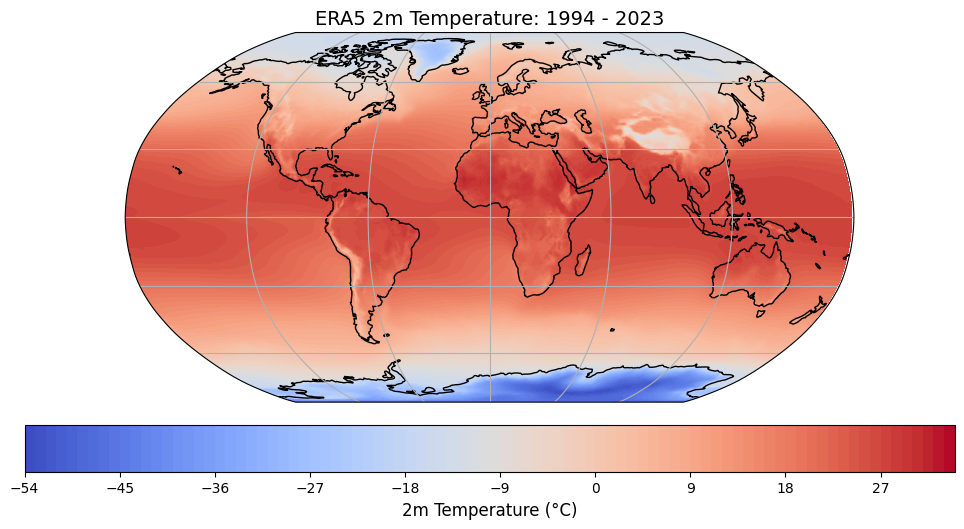

In [5]:
# Plotting the Interpolated Data

import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create a figure
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Plot the interpolated ERA5 data
era5_interp_plot = ax.contourf(
    model_lon_grid, model_lat_grid, era5_interpolated_clim_23,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",  # Colormap for temperature
    levels=100,       # Number of color levels
)

# Add coastlines and gridlines
ax.coastlines()
ax.gridlines()

# Add a colorbar
cbar = plt.colorbar(era5_interp_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label("2m Temperature (Â°C)", fontsize=12)

# Add a title
plt.title(f"ERA5 2m Temperature: 1994 - 2023", fontsize=14)

# Show the plot
plt.show()

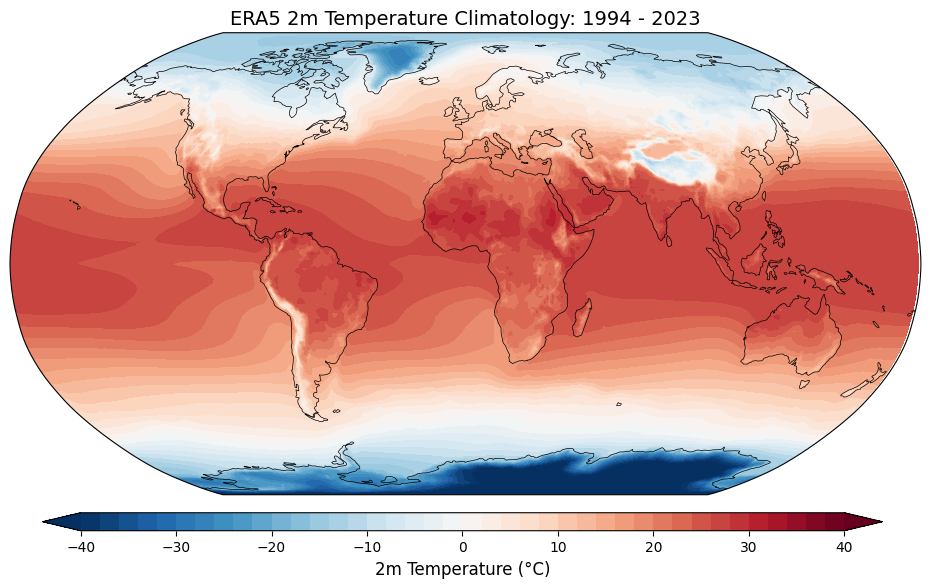

In [10]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap

# Create figure
fig = plt.figure(figsize=(12, 6))

# Define the projection
ax = plt.axes(projection=ccrs.Robinson())

# Define levels for the contour plot
num_levels = 41  # Number of color levels
levels = np.linspace(-40, 40, num_levels)  # Levels from -40Â°C to 40Â°C

# Plot the interpolated ERA5 data
era5_interp_plot = ax.contourf(
    model_lon_grid, model_lat_grid, era5_interpolated_clim_23,
    levels=levels,  # Use predefined levels
    cmap='RdBu_r',  # Use the reversed Red-Blue colormap
    vmin=-40,       # Set minimum value for colormap
    vmax=40,        # Set maximum value for colormap
    transform=ccrs.PlateCarree(),
    extend='both',  # Extend colormap to show values outside the range
)

# Add coastlines with a specified line width
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add a title
ax.set_title("ERA5 2m Temperature Climatology: 1994 - 2023", fontsize=14)

# Add a colorbar with better positioning
cbar_ax = fig.add_axes([0.16, 0.05, 0.7, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(era5_interp_plot, cax=cbar_ax, orientation='horizontal')
cbar.set_label("2m Temperature (Â°C)", fontsize=12)

# Show the plot
plt.show()

# Error